# ECB Monetary-Surprise Transmission: Empirical Thesis Companion

**Thesis focus.** This notebook presents the empirical evidence behind the thesis that post-COVID monetary expansion transmitted more strongly into housing, financial markets, and balance sheets than into real compensation dynamics.

The active empirical layer is a monthly reduced-form local-projection design using high-frequency ECB monetary-policy surprises. The notebook keeps the technical backbone intact, but the presentation is organized around economic interpretation rather than pipeline mechanics.


In [3]:
# Notebook controls.
REBUILD_RESULTS = True
SHOW_SUPPORTING_DIAGNOSTICS = False
SHOW_REPLICATION_APPENDIX = False

from pathlib import Path
import os
import sys

ROOT_MARKERS = (
    '1. thesis_master_notebook.ipynb',
    'scripts/run_full_pipeline.py',
    'src/notebook_utils/bootstrap.py',
)
ROOT_HINTS = [
    Path.cwd(),
    Path(os.environ.get('THESIS_MODEL_ROOT', '')).expanduser(),
    Path(globals().get('__vsc_ipynb_file__', '')).expanduser().parent,
]

for start in ROOT_HINTS:
    if not str(start):
        continue
    for candidate in [start.resolve(), *start.resolve().parents]:
        if all((candidate / marker).exists() for marker in ROOT_MARKERS):
            sys.path.insert(0, str(candidate))
            break
    else:
        continue
    break
else:
    raise RuntimeError('Could not locate THESIS_Model root; set THESIS_MODEL_ROOT to the project folder.')

from src.notebook_utils.bootstrap import *

configure_notebook()


In [4]:
major_output_status = display_rebuild_and_validation(REBUILD_RESULTS)


_Refreshing the stored empirical outputs before rendering the notebook._

_Empirical outputs refreshed; rendering thesis presentation._

## 1. Research Motivation

The post-COVID monetary environment created an unusually clear setting for studying asymmetric transmission. Liquidity expanded rapidly, policy rates remained highly accommodative for an extended period, and financial conditions moved before household purchasing power fully adjusted.

The central empirical question is whether expansionary monetary policy primarily supported broad real-income growth, or whether its strongest and most persistent effects appeared in asset-linked channels such as housing finance, equities, lending conditions, and balance sheets.

The thesis interpretation is comparative: monetary easing appears to reach housing and financial asset prices more forcefully than real wages or broad compensation. This does not require every asset variable to move identically; it requires the overall response hierarchy to be stronger in asset-linked channels than in labor-income dynamics.


## 2. Data And Variable Construction

The data are selected to match economic roles rather than implementation convenience. Housing variables capture the credit and affordability side of the housing market; financial variables capture market repricing and balance-sheet conditions; intermediation variables capture the pricing and timing of credit transmission.

Compensation is necessarily measured through monthly proxies. Direct compensation per employee is quarterly, so the notebook uses official monthly wage-pressure and wage-bill measures to study whether labor income responds with comparable strength and persistence.


In [5]:
display_data_coverage()


**Empirical Sample Window**

Sample,Sample start,Sample end,Interpretation
Monthly euro-area / Germany empirical panel,2005-01,2025-10,Monthly policy-news design with official macro-financial and proxy variables aligned to the response horizon.


**Core Variable Coverage**

Variable,Sample start,Sample end,Observations
bls_credit_standards_mortgage_q_observed,2005-03-31,2025-09-30,83
bls_loan_demand_mortgage_q_observed,2005-03-31,2025-09-30,83
ecb_house_purchase_growth_yoy,2005-01-31,2025-10-31,250
ecb_mir_mortgage_lending_spread_dfr,2005-01-31,2025-10-31,250
ecb_mir_nfc_lending_spread_dfr,2005-01-31,2025-10-31,250
ecb_wage_tracker_ex_oneoffs_real_yoy,2013-01-31,2025-10-31,154
eurostat_sts_industry_wage_bill_de_real_yoy,2006-01-31,2025-10-31,238
ln_dax_real_de,2005-01-31,2025-10-31,250


**Quarter-End Variables Kept As Observed**

Response,Comments
ln_house_price_de_real_q_observed,Quarterly housing series is sparse at quarter-end only; not interpolated.
ln_compensation_ea20_real_q_observed,Quarterly compensation series is sparse at quarter-end only; not interpolated.


**Frequency Summary**

Monthly Status,Identification Role,Variables
monthly_or_event_monthly,monthly_model_candidate,95
monthly_or_event_monthly,external_policy_surprise_candidate,30
monthly_or_event_monthly,metadata,22
quarterly_observed_only_no_interpolation,monthly_model_candidate,18
quarterly_observed_only_no_interpolation,metadata,6


In [6]:
display_variable_dictionary()


**Thesis Variable Map**

Variable,Economic role,Interpretation,Comments
target_factor_monthly_easing,Policy surprise,High-frequency ECB target surprise aggregated to the month; positive values denote easing news.,The shock is normalized to one standard deviation in the IRFs.
ln_ecb_assets_ea_stock,Liquidity / balance sheet,Eurosystem balance-sheet stock used to separate liquidity context from target-rate surprises.,"Useful for balance-sheet inflation context, not a pure QE treatment in the baseline."
ln_dax_real_de,Financial asset price,Real German equity-market proxy capturing fast financial-market repricing.,Interpreted as an asset-price response to monetary news.
ln_nfc_loans_ea_stock,Productive credit,Credit stock to non-financial corporations.,Tests whether productive-credit expansion dominates the response hierarchy.
ecb_mir_mortgage_lending_spread_dfr,Housing finance price,Mortgage lending spread over the deposit facility rate.,Links policy news to housing affordability and credit pricing.
ecb_mir_nfc_lending_spread_dfr,Business credit price,NFC lending spread over the deposit facility rate.,Useful comparison for housing versus productive-credit transmission.
ecb_house_purchase_growth_yoy,Housing finance quantity,Annual growth in house-purchase lending.,One of the central variables for the housing-channel result.
ln_ecb_house_purchase_pure_new_loans,Housing finance flow,Monthly volume of pure new loans for house purchase.,Complements lending-growth evidence with a flow-based housing-finance proxy.


**Accepted Proxy Roles And Comments**

Domain,Role,Variable,Label,Economic interpretation,Comments
compensation,canonical,ecb_wage_tracker_ex_oneoffs_real_yoy,"ECB Wage Tracker excluding one-off payments, real",Monthly real negotiated wage pressure excluding one-off payments.,"It is negotiated wage pressure, not observed total compensation per employee, payroll income, welfare, or redistribution."
compensation,diagnostic,ecb_wage_tracker_ex_oneoffs_real_yoy_momentum_3m,"ECB Wage Tracker excluding one-offs, real 3-month momentum",Three-month change in real negotiated wage pressure excluding one-off payments.,Momentum is mechanically noisier than the level and is not used as the primary compensation proxy.
compensation,diagnostic_short_sample,ecb_ces_real_income_expectations_12m_median,ECB CES real household income expectations,Weighted median expected household income growth over the next 12 months minus HICP inflation.,Short public CES sample makes it unsuitable as the main long-window compensation proxy.
compensation,diagnostic_short_sample,ecb_ces_unemployment_expectations_12m_median,ECB CES expected unemployment rate,Weighted median expected unemployment rate over the next 12 months.,Short sample and expectation construct prevent main compensation use.
compensation,indirect,eurostat_ecfin_eei_ea20,European Commission employment expectations indicator,Monthly euro-area employment expectations indicator over the next three months.,Survey expectations are indirect wage-pressure evidence and can revise with seasonal adjustment.
compensation,indirect,eurostat_ecfin_services_employment_expectations_ea20,European Commission services employment expectations,Monthly euro-area services employment expectations balance.,"It captures expected services employment, not observed services wages."
compensation,indirect,eurostat_labor_tightness_unemployment_inv,Eurostat unemployment inverse labor-tightness proxy,Negative of the monthly seasonally adjusted euro-area unemployment rate.,"Labor tightness is an indirect wage-pressure proxy, not compensation or wage growth."
compensation,robustness,ecb_wage_tracker_ex_oneoffs_real_yoy_ma3,"ECB Wage Tracker excluding one-offs, real 3-month average",Three-month average of monthly real negotiated wage pressure excluding one-off payments.,Smoothing is transparent and only uses observed current/past monthly data; it is not a distinct source series.


## 3. Identification Strategy

Identification comes from high-frequency ECB monetary-policy surprises aggregated to monthly frequency. These announcement-window surprises isolate policy news before monthly macro-financial outcomes are realized, allowing the notebook to trace dynamic responses after easing shocks.

The first-stage evidence is used as context for instrument strength and sample stability. An F-statistic around 17 is treated as usable and economically informative, while the final interpretation remains reduced-form rather than a strict structural treatment-bridge claim.


In [7]:
display_instrument_validity()


**Identification Strategy In One Line**

Identification Object,Economic role,Interpretation,Comments
High-frequency ECB target surprises,Exogenous monetary-policy news,Announcement-window surprises are predetermined relative to monthly macro-financial outcomes and can be used to trace dynamic responses.,"Information-effect screens and first-stage checks are used as measurement context, not as a competing technical narrative."


**Instrument Strength Context**

Policy bridge,Instrument,Observations,First-stage F-stat,Partial R-squared,Rolling sign stability,Comments
"deposit facility rate, end of month",target_factor_monthly_easing,246,17.0721,0.0664,1.0000,An F-statistic near 17 is statistically usable and economically informative. Rolling and regime variation motivates reduced-form language...


In [8]:
if SHOW_SUPPORTING_DIAGNOSTICS:
    display_information_effects()


## 4. Baseline Results

The baseline IRFs are the empirical centerpiece. They show how each channel responds over monthly horizons after an ECB easing surprise, and they make the core asymmetry visually explicit: housing and financial channels carry more of the transmission than real compensation dynamics.


In [9]:
empirical_context = display_irf_and_persistence_summaries()


**Empirical Object**

Main Shock,Shock Normalization,Horizon Grid Months,Responses Estimated,Interpretation,Uncertainty
target_factor_monthly_easing,1_sd_surprise,"0, 1, 3, 6, 12, 24",22,Monthly local projections trace the response of each variable to a one-standard-deviation ECB easing surprise.,HAC/Newey-West plus bootstrap bands where feasible


**Normalized IRFs At Thesis Horizons**

Variable,Economic channel,Horizon (months),Response,90 Percent Interval,Thesis reading
house-purchase lending growth,housing_finance,0,0.0482,"[0.013, 0.084]",Core asset-linked channel; central to the thesis.
house-purchase lending growth,housing_finance,6,0.1487,"[0.077, 0.221]",Core asset-linked channel; central to the thesis.
house-purchase lending growth,housing_finance,12,0.0986,"[-0.015, 0.212]",Core asset-linked channel; central to the thesis.
house-purchase lending growth,housing_finance,24,-0.1262,"[-0.290, 0.037]",Core asset-linked channel; central to the thesis.
pure new house-purchase loans,housing_finance,0,-0.0070,"[-0.027, 0.013]",Core asset-linked channel; central to the thesis.
pure new house-purchase loans,housing_finance,6,0.0197,"[-0.002, 0.041]",Core asset-linked channel; central to the thesis.
pure new house-purchase loans,housing_finance,12,-0.0013,"[-0.023, 0.020]",Core asset-linked channel; central to the thesis.
pure new house-purchase loans,housing_finance,24,-0.0308,"[-0.075, 0.014]",Core asset-linked channel; central to the thesis.


**Cumulative Persistence At 12 And 24 Months**

Variable,Economic channel,Horizon (months),Cumulative response,90 Percent Interval,Visibility,Thesis reading
house-purchase lending growth,housing_finance,12,0.4832,"[0.327, 0.640]",visible,Core asset-linked channel; central to the thesis.
house-purchase lending growth,housing_finance,24,0.3570,"[0.131, 0.583]",visible,Core asset-linked channel; central to the thesis.
pure new house-purchase loans,housing_finance,12,0.0253,"[-0.021, 0.071]",limited precision,Core asset-linked channel; central to the thesis.
pure new house-purchase loans,housing_finance,24,-0.0055,"[-0.070, 0.059]",limited precision,Core asset-linked channel; central to the thesis.
real DAX,financial_market,12,-0.0396,"[-0.065, -0.014]",visible,Fast financial-market repricing; supports asset-price transmission.
real DAX,financial_market,24,-0.0668,"[-0.100, -0.033]",visible,Fast financial-market repricing; supports asset-price transmission.
NFC lending rate,banking_lending_conditions,12,-0.0246,"[-0.124, 0.074]",limited precision,Lending-condition channel connects policy news to credit pricing.
NFC lending rate,banking_lending_conditions,24,0.0128,"[-0.130, 0.156]",limited precision,Lending-condition channel connects policy news to credit pricing.


**Peak-Response Summary**

Variable,Economic channel,Peak horizon,Peak response,90 Percent Interval,Thesis reading
house-purchase lending growth,housing_finance,6,0.1487,"[0.077, 0.221]",Core asset-linked channel; central to the thesis.
pure new house-purchase loans,housing_finance,24,-0.0308,"[-0.075, 0.014]",Core asset-linked channel; central to the thesis.
real DAX,financial_market,24,-0.0272,"[-0.049, -0.006]",Fast financial-market repricing; supports asset-price transmission.
NFC lending rate,banking_lending_conditions,24,0.0375,"[-0.066, 0.141]",Lending-condition channel connects policy news to credit pricing.
NFC lending spread,banking_lending_conditions,12,0.0252,"[0.006, 0.045]",Lending-condition channel connects policy news to credit pricing.
mortgage lending rate,banking_lending_conditions,24,0.0338,"[-0.039, 0.106]",Lending-condition channel connects policy news to credit pricing.
mortgage lending spread,banking_lending_conditions,12,0.0500,"[0.007, 0.093]",Lending-condition channel connects policy news to credit pricing.
ECB assets,financial_liquidity,24,-0.0106,"[-0.035, 0.014]",Balance-sheet context; useful but less direct under target surprises.


### Baseline Normalized IRFs

#### Baseline IRF: ECB assets


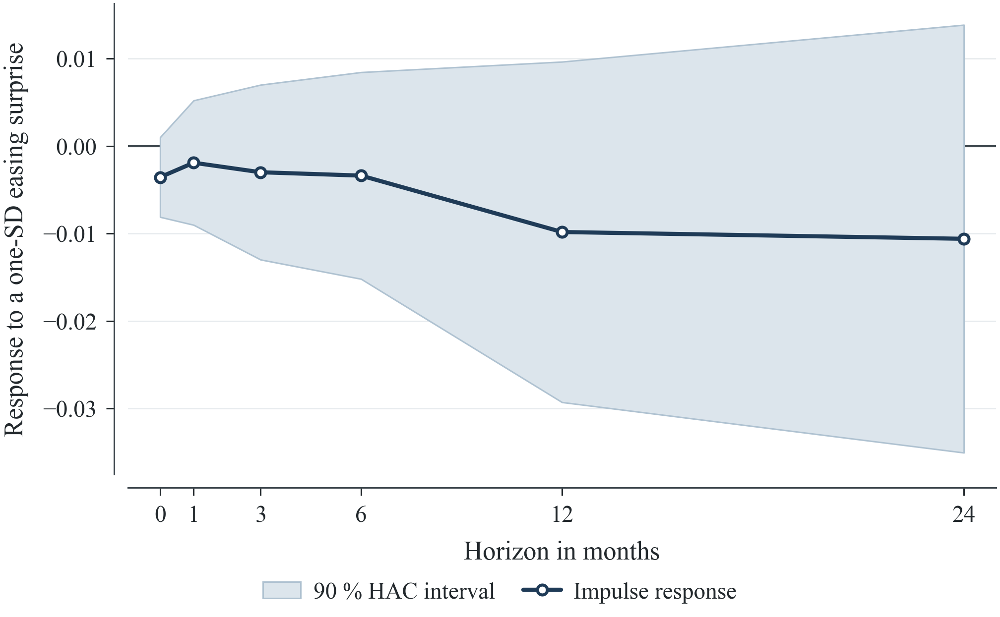

#### Baseline IRF: real DAX


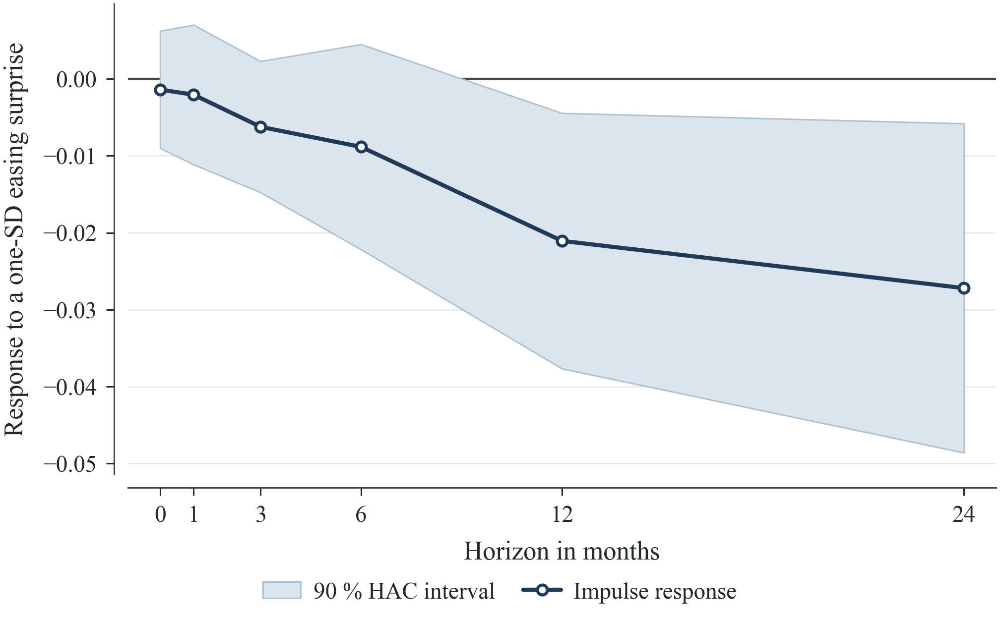

#### Baseline IRF: NFC credit


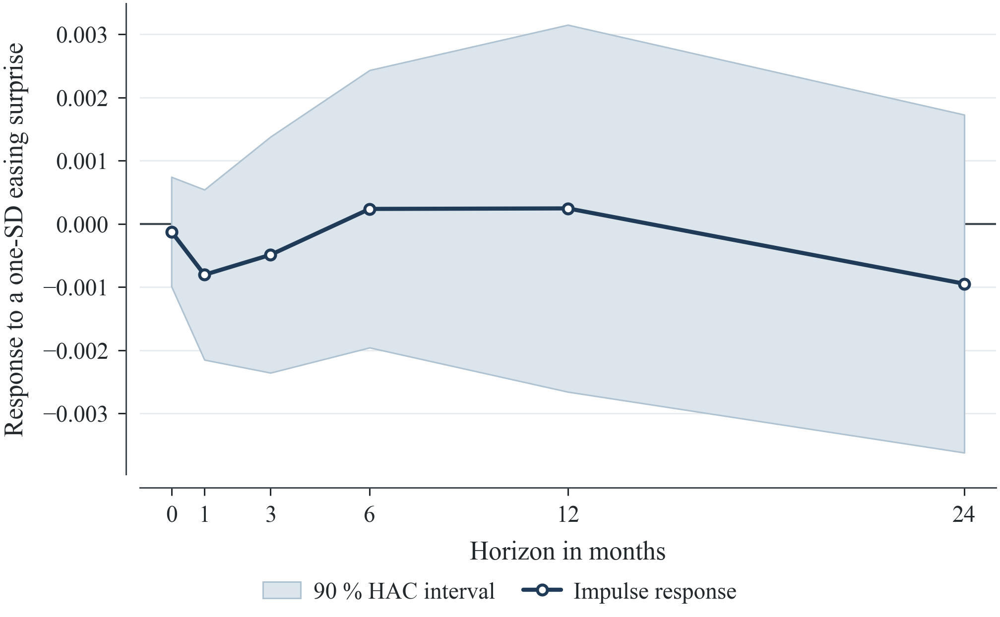

#### Baseline IRF: mortgage lending spread


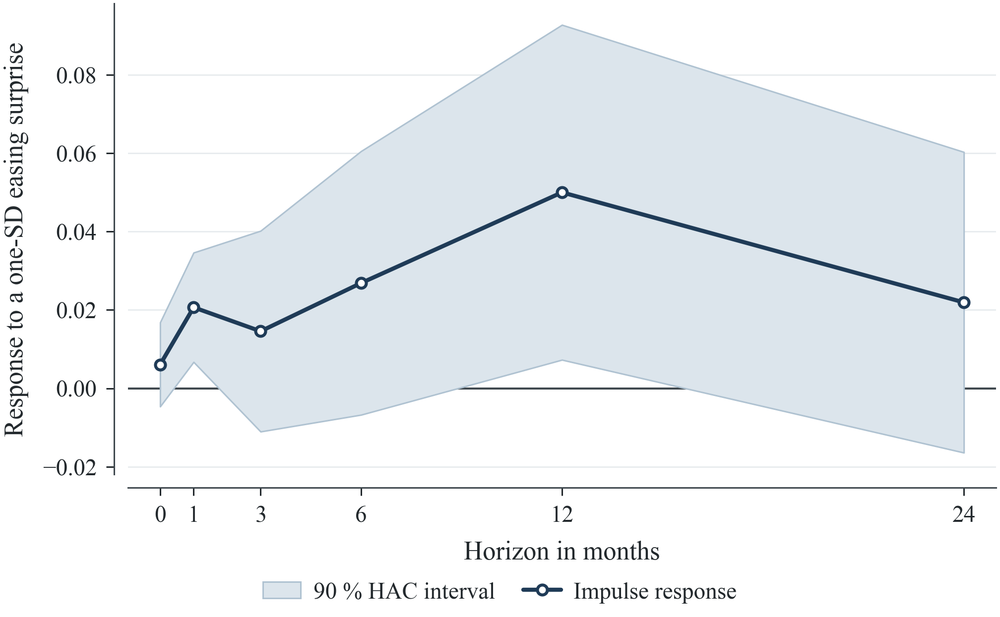

#### Baseline IRF: NFC lending spread


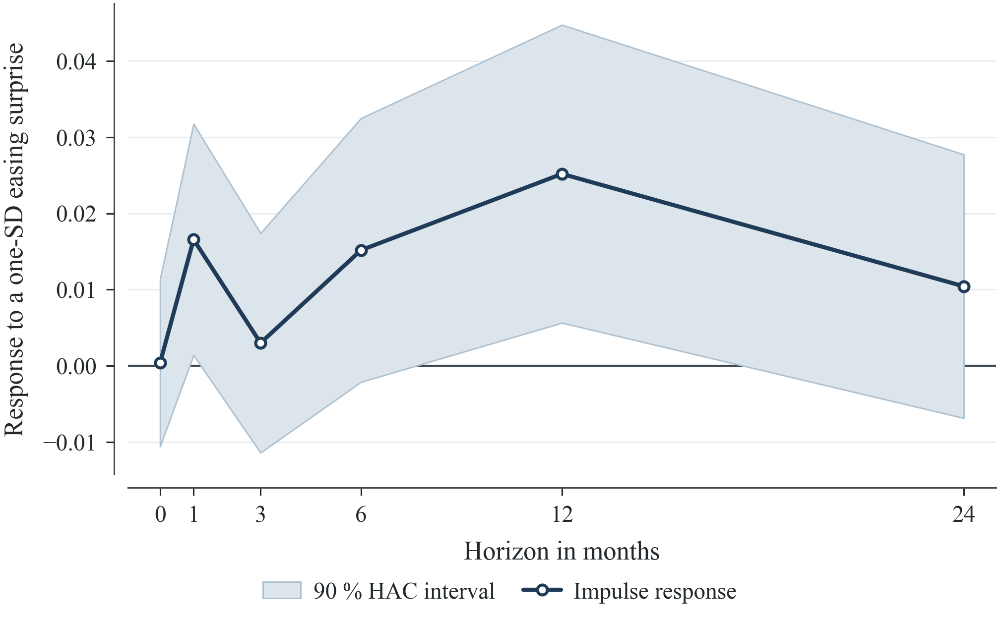

#### Baseline IRF: house-purchase lending growth


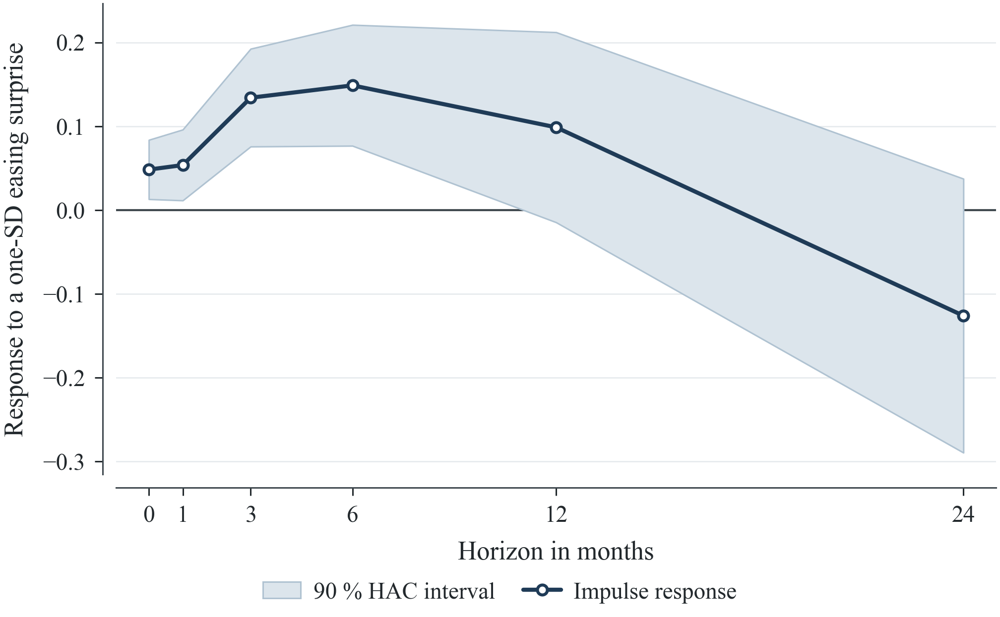

#### Baseline IRF: pure new house-purchase loans


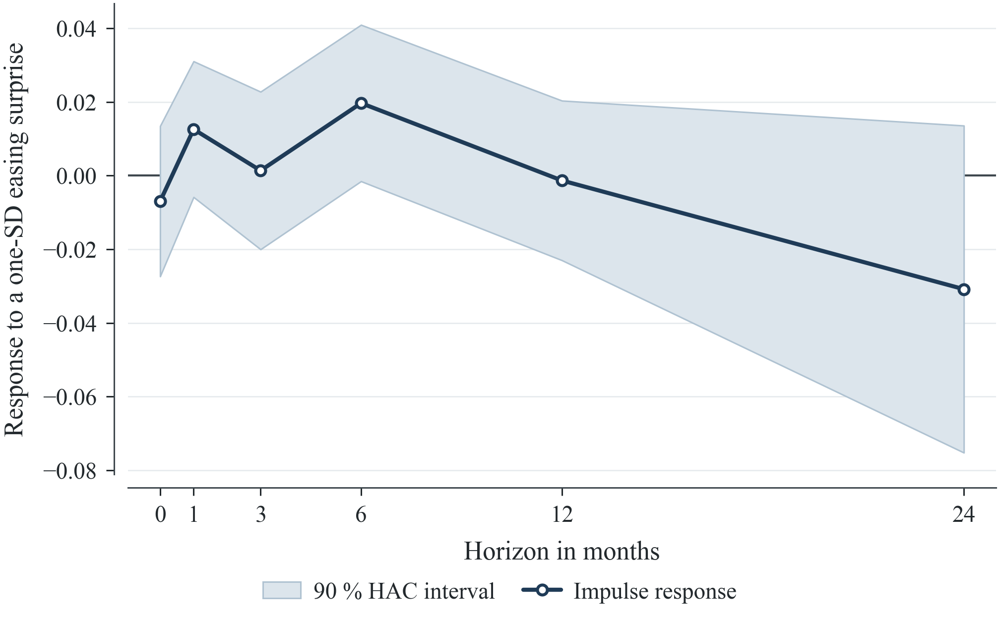

#### Baseline IRF: real wage tracker excluding one-offs


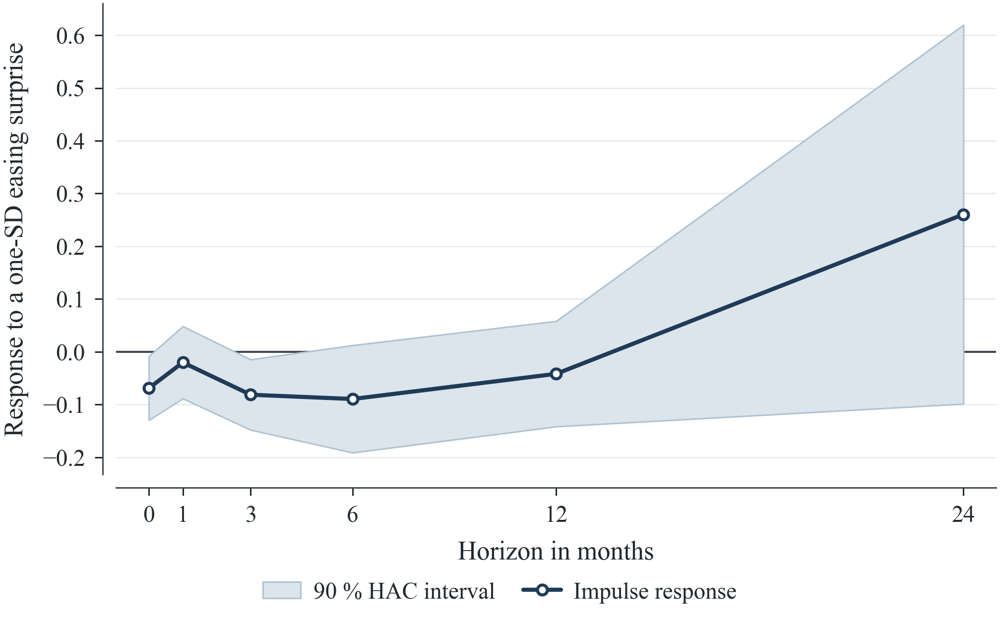

#### Baseline IRF: German industry real wage bill growth


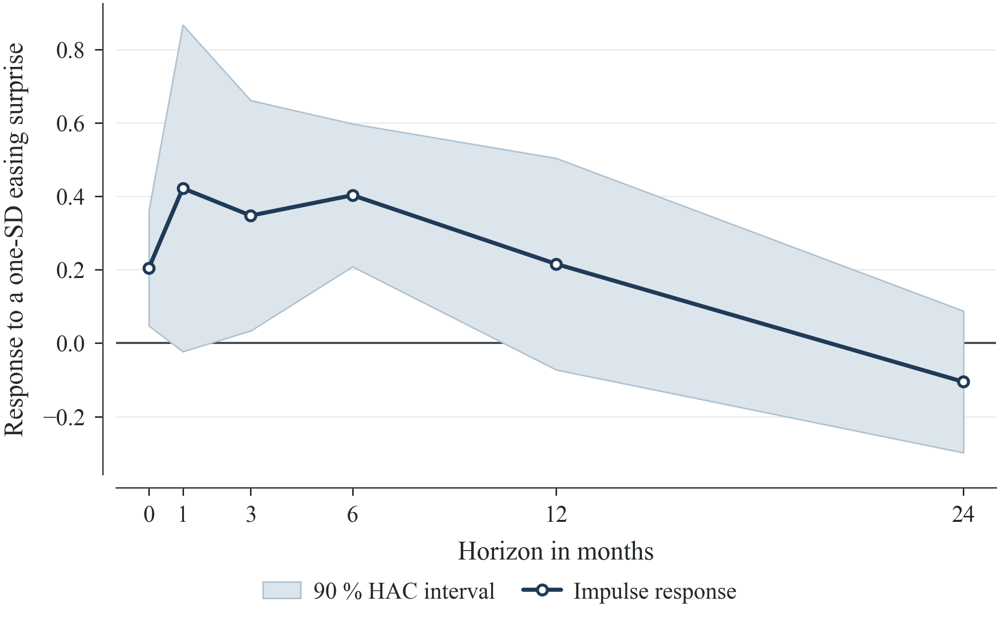

#### Baseline IRF: employment expectations


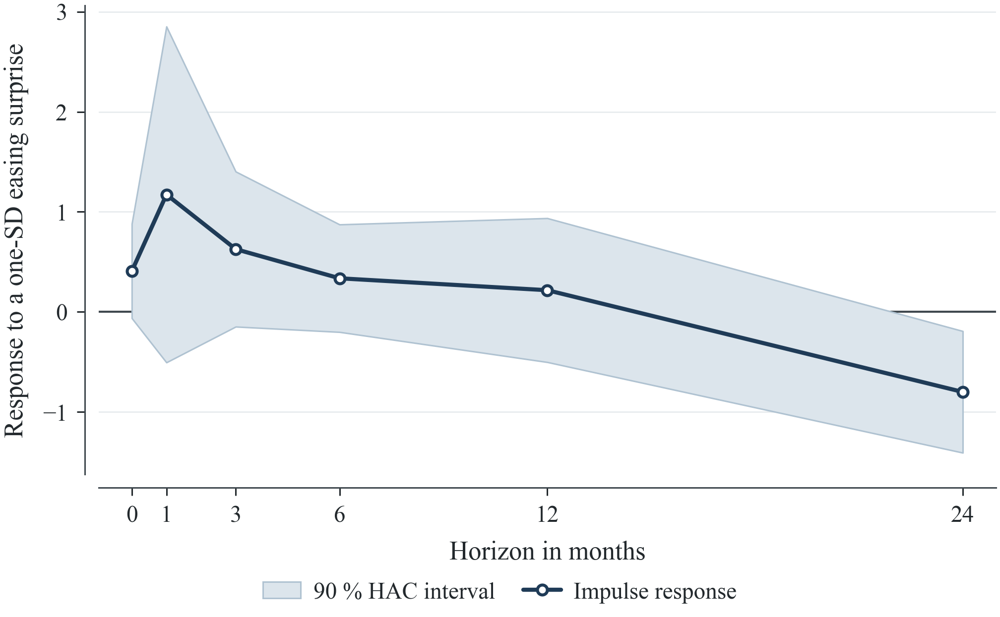

In [10]:
display_baseline_irf_figures()


### Cumulative IRFs

#### Cumulative Response: ECB assets


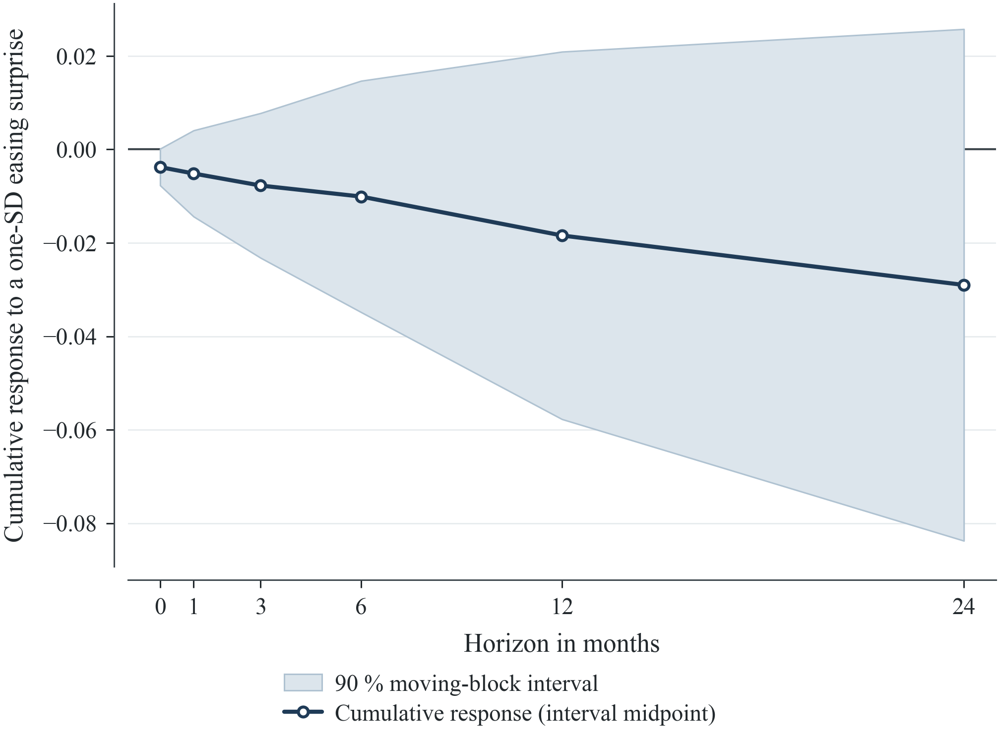

#### Cumulative Response: real DAX


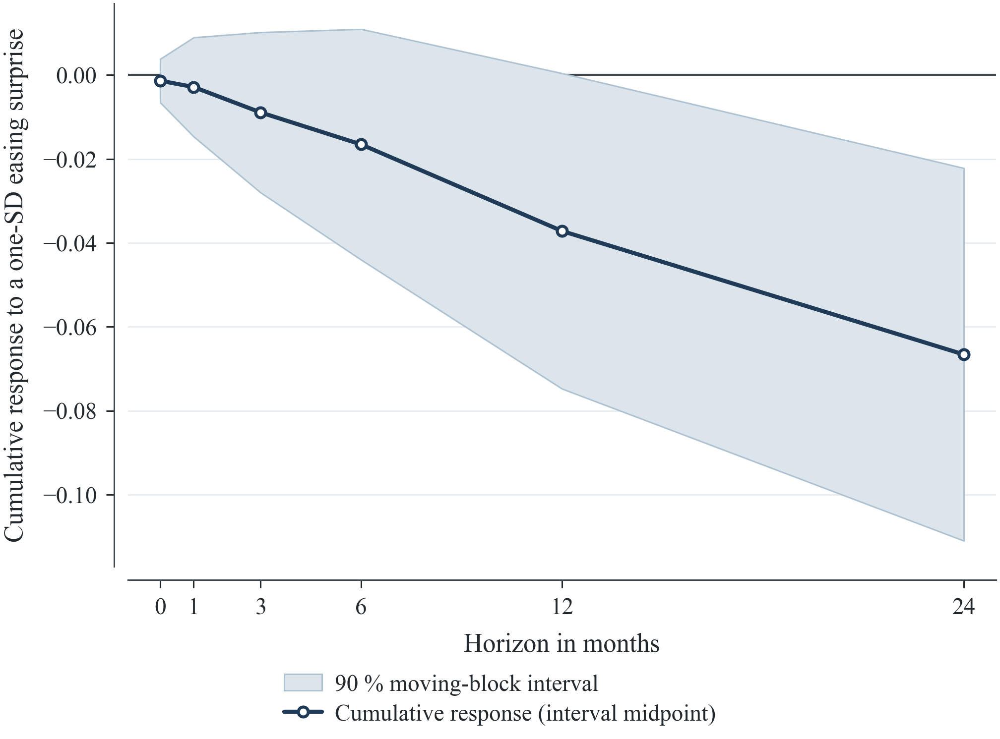

#### Cumulative Response: NFC credit


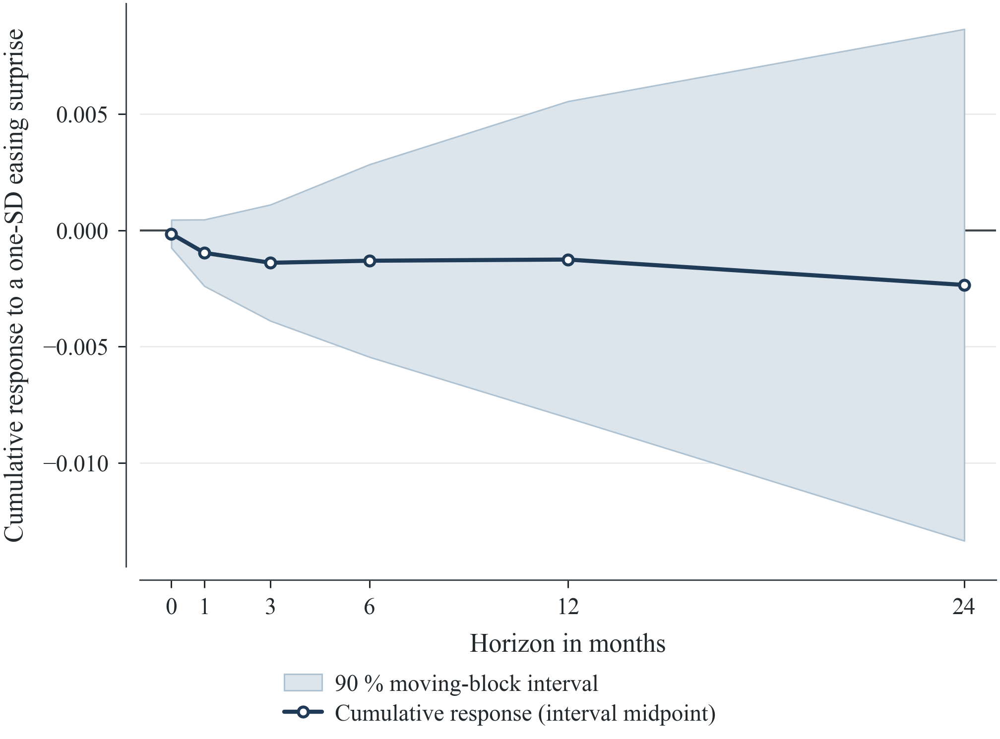

#### Cumulative Response: mortgage lending spread


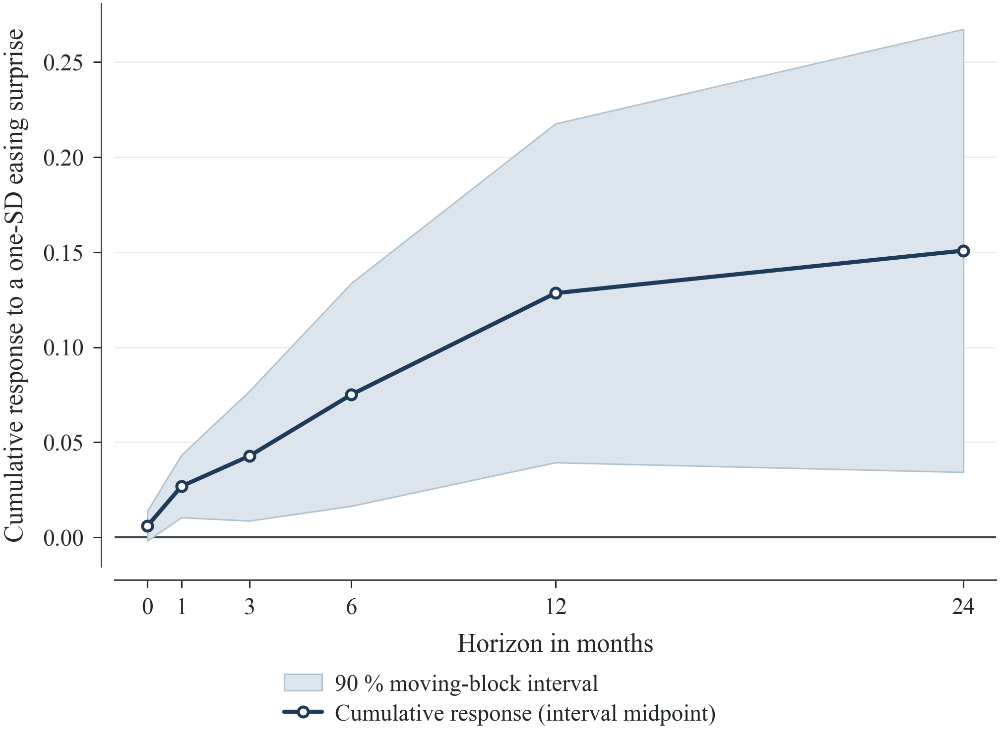

#### Cumulative Response: NFC lending spread


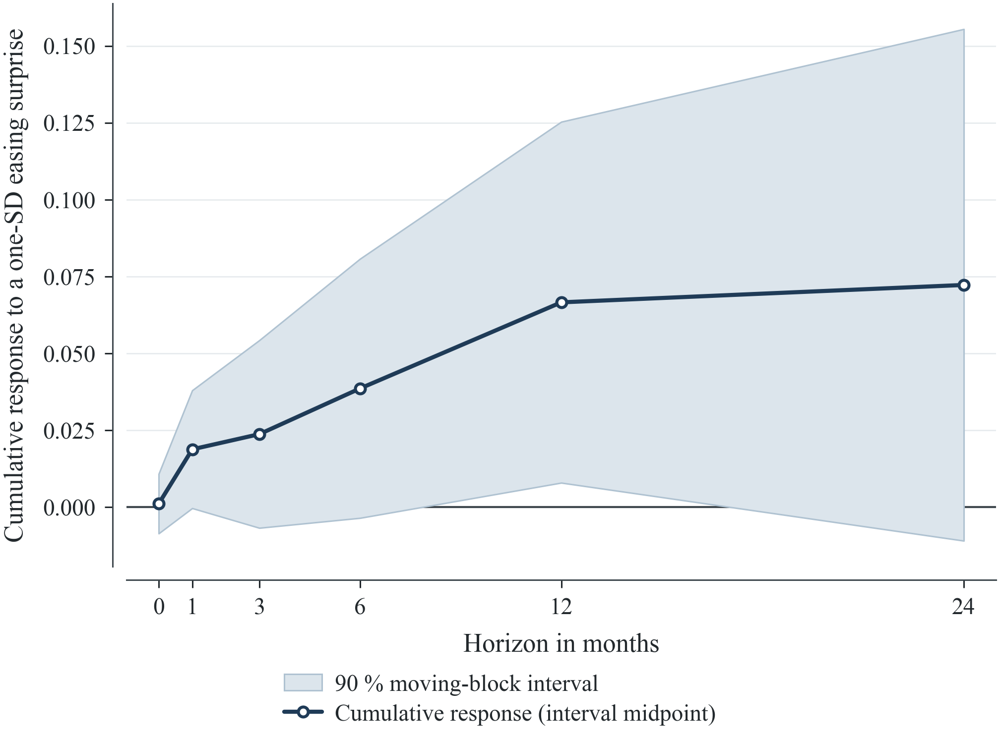

#### Cumulative Response: house-purchase lending growth


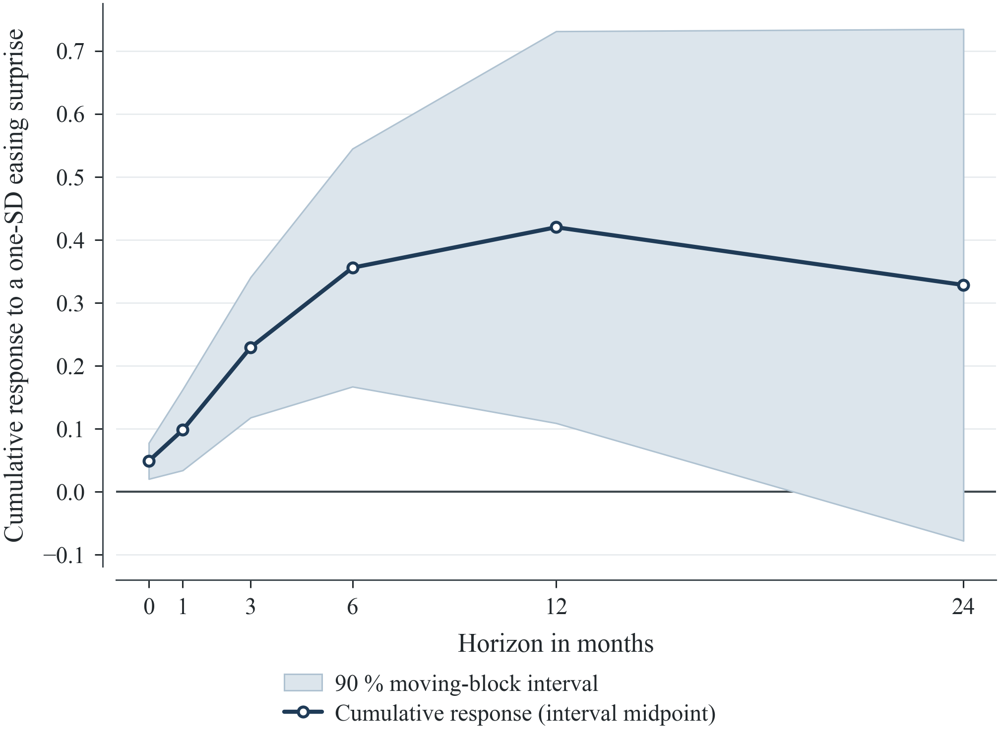

#### Cumulative Response: pure new house-purchase loans


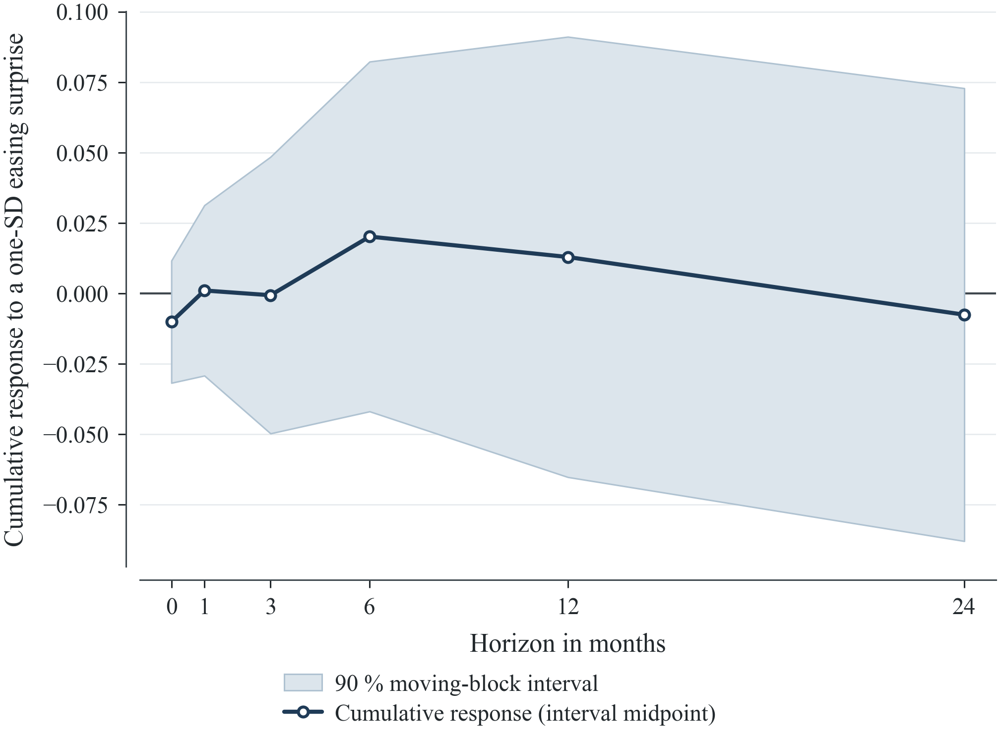

#### Cumulative Response: real wage tracker excluding one-offs


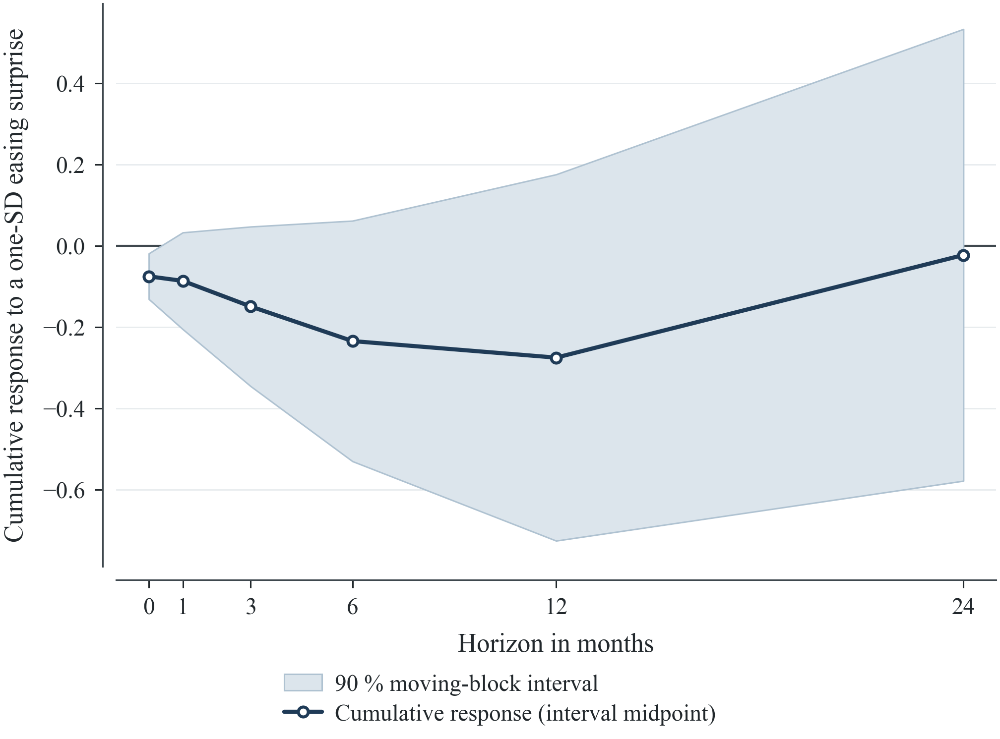

#### Cumulative Response: German industry real wage bill growth


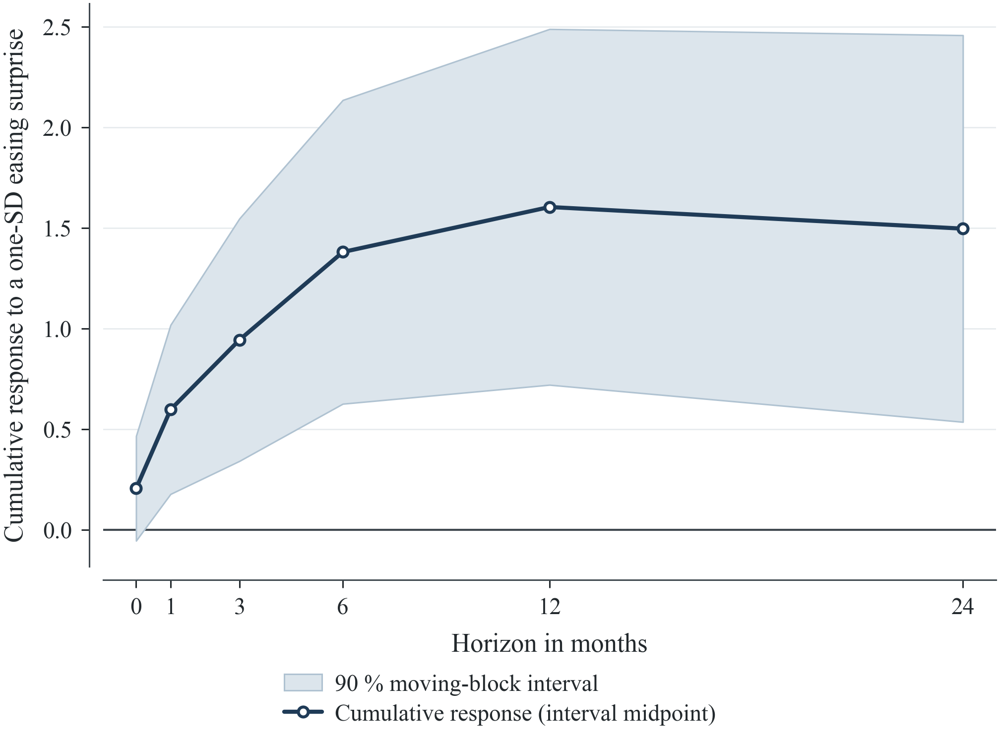

#### Cumulative Response: employment expectations


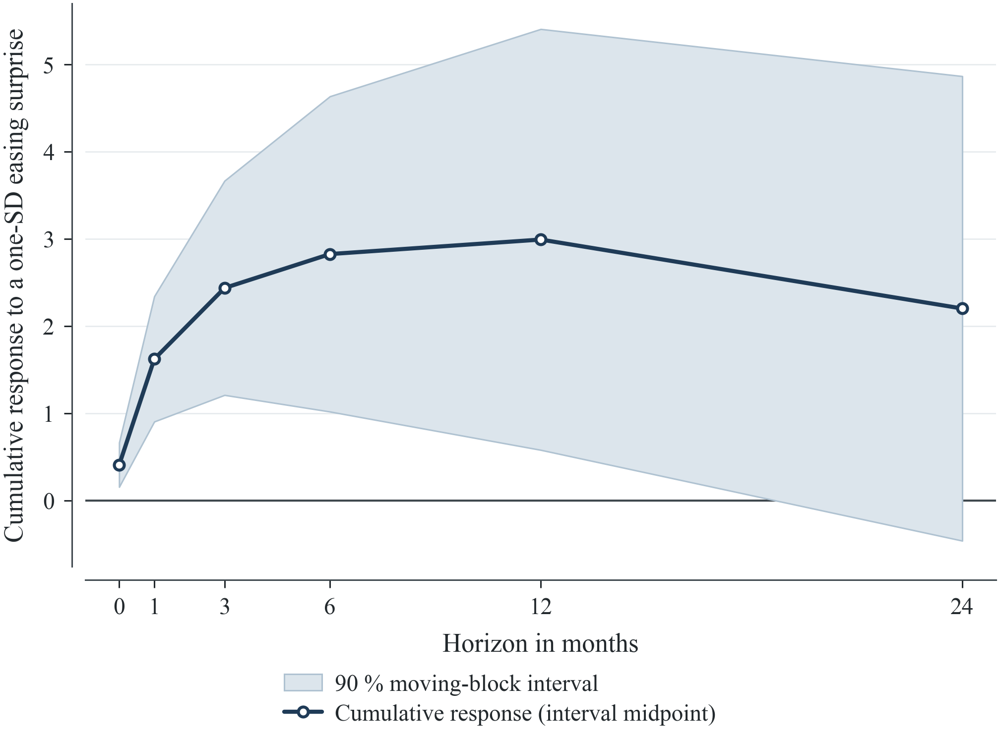

In [11]:
display_cumulative_irf_figures()


## 5. Comparative Transmission Analysis

This section compares the response hierarchy directly. The relevant contrast is not whether one variable is the single largest at every horizon, but whether asset-linked and housing channels show clearer, more persistent transmission than wage and compensation proxies.


**Cross-Variable Transmission Ranking**

Variable,Economic channel,Peak response,Peak horizon,24-month cumulative response,Persistence reading,Thesis reading
house-purchase lending growth,housing_finance,0.1487,6,0.3570,persistent cumulative,Asset-linked transmission is economically stronger.
pure new house-purchase loans,housing_finance,-0.0308,24,-0.0055,limited / uncertain,Asset-linked transmission is economically stronger.
real DAX,financial_market,-0.0272,24,-0.0668,persistent cumulative,Asset-linked transmission is economically stronger.
NFC lending rate,banking_lending_conditions,0.0375,24,0.0128,limited / uncertain,Asset-linked transmission is economically stronger.
NFC lending spread,banking_lending_conditions,0.0252,12,0.0707,persistent cumulative,Asset-linked transmission is economically stronger.
mortgage lending rate,banking_lending_conditions,0.0338,24,0.0600,limited / uncertain,Asset-linked transmission is economically stronger.
mortgage lending spread,banking_lending_conditions,0.0500,12,0.1401,persistent cumulative,Asset-linked transmission is economically stronger.
ECB assets,financial_liquidity,-0.0106,24,-0.0323,limited / uncertain,Useful supporting channel in the transmission hierarchy.


### Comparative Transmission Analysis

#### Comparative IRF Panel


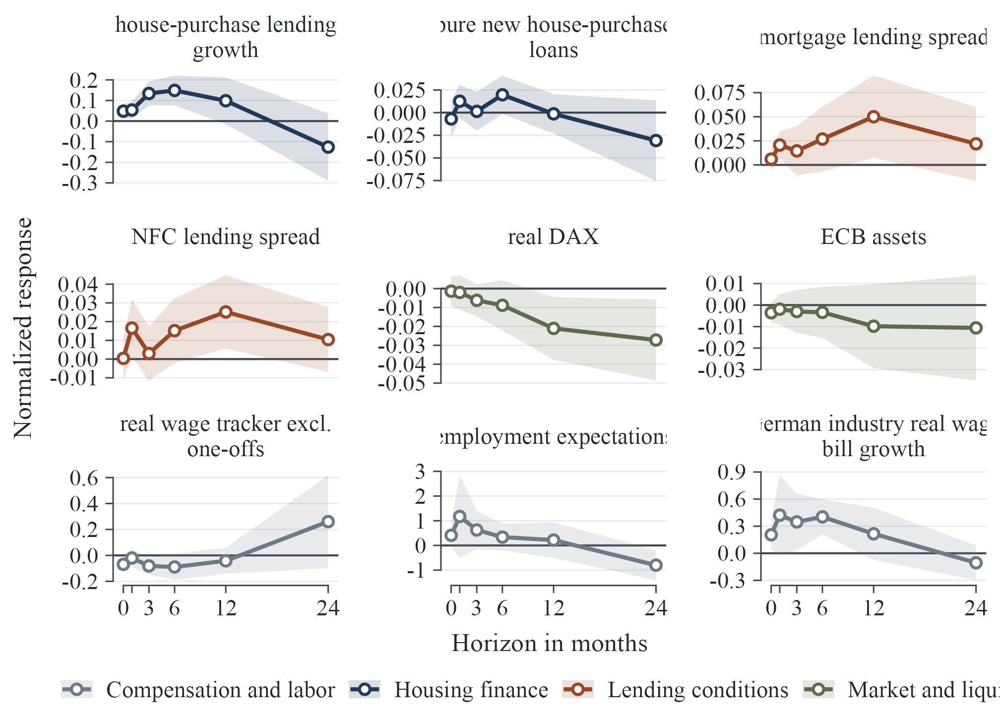

#### Horizon Durability Matrix


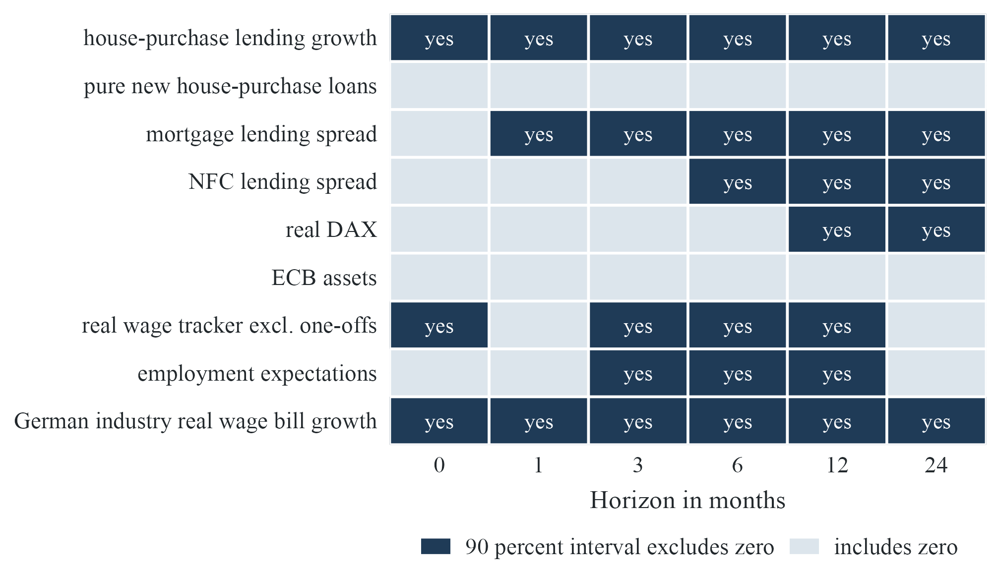

#### Sign Persistence Map


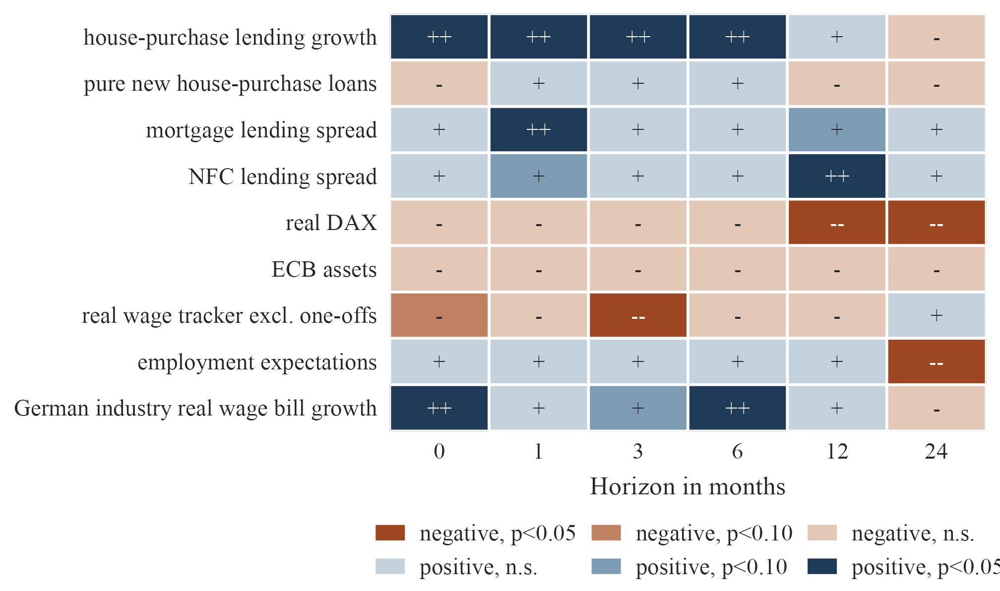

#### Affordability Transmission Flow


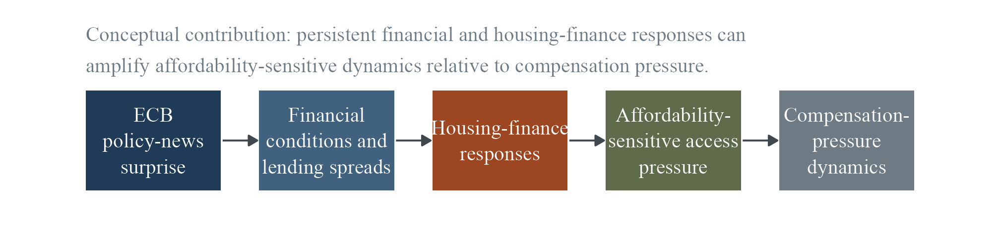

In [13]:
comparison = display_cross_variable_comparison(empirical_context)


**Intermediation Variables**

Variable,Label,Proxy Type,Frequency,Comments
ecb_mir_mortgage_lending_rate,ECB MIR mortgage lending rate,lending_rate,monthly,Monthly observed annualised agreed rate on new euro-area house-purchase loans.
ecb_mir_nfc_lending_rate,ECB MIR NFC lending rate,lending_rate,monthly,Monthly observed annualised agreed rate on new euro-area NFC loans.
ecb_mir_mortgage_lending_spread_dfr,Mortgage lending spread over DFR,lending_spread,monthly,Computed as monthly MIR mortgage lending rate minus monthly average DFR.
ecb_mir_nfc_lending_spread_dfr,NFC lending spread over DFR,lending_spread,monthly,Computed as monthly MIR NFC lending rate minus monthly average DFR.
ln_hh_loans_ea_stock,Household credit stock,credit_stock,monthly,Monthly ECB MFI loans to households; broad fallback credit stock.
ln_nfc_loans_ea_stock,NFC credit stock,credit_stock,monthly,Monthly ECB adjusted MFI loans to non-financial corporations.
ecb_house_purchase_growth_yoy,House-purchase lending growth,housing_finance,monthly,Monthly ECB annual growth in loans for house purchase.
ln_ecb_house_purchase_pure_new_loans,Pure new house-purchase loans,housing_finance,monthly,Monthly ECB MIR pure new loans for house purchase; shorter public sample.


**Intermediation Timing And Economic Role**

Variable,Economic channel,Peak horizon,Peak response,Cumulative response,Direction,Thesis reading
house-purchase lending growth,housing_finance,6.0000,0.1487,0.3570,positive,Core asset-linked channel; central to the thesis.
pure new house-purchase loans,housing_finance,24.0000,-0.0308,-0.0055,negative,Core asset-linked channel; central to the thesis.
NFC lending rate,banking_lending_conditions,24.0000,0.0375,0.0128,positive,Lending-condition channel connects policy news to credit pricing.
NFC lending spread,banking_lending_conditions,12.0000,0.0252,0.0707,positive,Lending-condition channel connects policy news to credit pricing.
mortgage lending rate,banking_lending_conditions,24.0000,0.0338,0.0600,positive,Lending-condition channel connects policy news to credit pricing.
mortgage lending spread,banking_lending_conditions,12.0000,0.0500,0.1401,positive,Lending-condition channel connects policy news to credit pricing.
NFC credit,financial_credit,24.0000,-0.0009,-0.0019,negative,Credit-stock response is weaker than housing-finance evidence.
household credit,financial_credit,24.0000,-0.0014,-0.0011,negative,Credit-stock response is weaker than housing-finance evidence.


**Spread Responses**

Variable,Economic channel,Peak horizon,Peak response,Cumulative response,Direction,Timing note
NFC lending spread,banking_lending_conditions,12.0000,0.0252,0.0707,positive,NaN
mortgage lending spread,banking_lending_conditions,12.0000,0.0500,0.1401,positive,NaN


### Mechanism And Banking

#### Banking Peak Timing


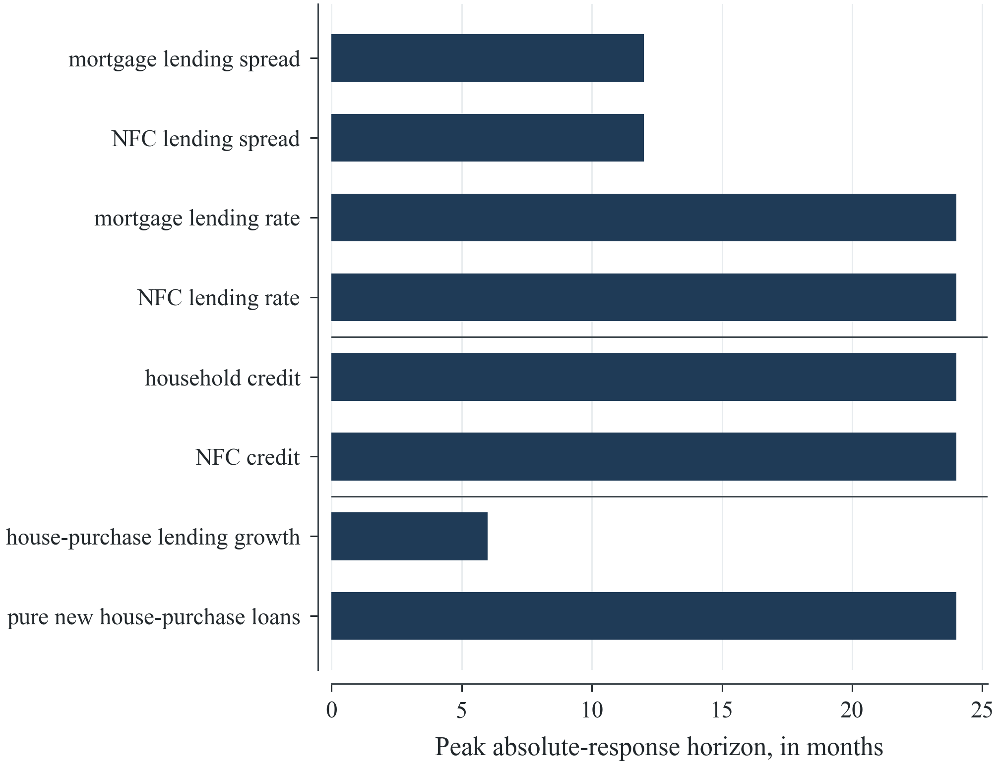

#### Sequential Timing Response Map


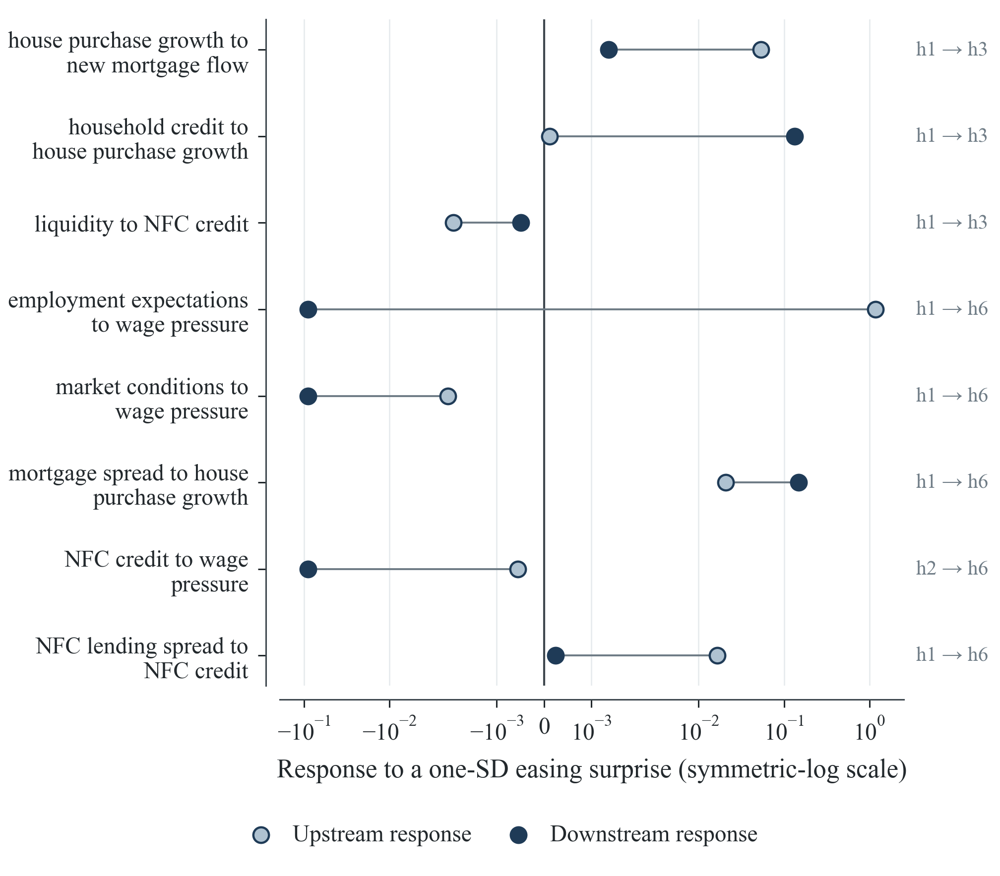

**Sequential Timing Pathways**

Pathway,Earlier response,Later response,Upstream Horizon Months,Downstream Horizon Months,Timing reading,Comments
mortgage_spread_to_house_purchase_growth,mortgage lending spread,house-purchase lending growth,1,6,ordered_dynamic_transmission,Timing evidence only; this is not structural bank-channel identification.
nfc_lending_spread_to_nfc_credit,NFC lending spread,NFC credit,1,6,ordered_dynamic_transmission,Timing evidence only; this is not structural bank-channel identification.
liquidity_to_nfc_credit,ECB assets,NFC credit,1,3,ordered_dynamic_transmission,Timing evidence only; this is not structural bank-channel identification.
household_credit_to_house_purchase_growth,household credit,house-purchase lending growth,1,3,ordered_dynamic_transmission,Timing evidence only; this is not structural bank-channel identification.
house_purchase_growth_to_new_mortgage_flow,house-purchase lending growth,pure new house-purchase loans,1,3,ordered_dynamic_transmission,Timing evidence only; this is not structural bank-channel identification.
nfc_credit_to_wage_pressure,NFC credit,real wage tracker excl. one-offs,2,6,ordered_dynamic_transmission,Timing evidence only; this is not structural bank-channel identification.
employment_expectations_to_wage_pressure,employment expectations,real wage tracker excl. one-offs,1,6,ordered_dynamic_transmission,Timing evidence only; this is not structural bank-channel identification.
market_conditions_to_wage_pressure,real DAX,real wage tracker excl. one-offs,1,6,ordered_dynamic_transmission,Timing evidence only; this is not structural bank-channel identification.


**Policy Shock To Balance-Sheet Transmission**

Stage,Transmission layer,Active variables,Interpretation
1,Policy shock,target_factor_monthly_easing,"High-frequency ECB surprise, signed as easing"
2,Intermediation,"ECB assets, lending rates, mortgage/NFC spreads, BLS credit standards and loan demand","Liquidity, funding, and loan-supply timing"
3,Asset prices / housing finance,"real DAX, house-purchase lending growth, pure new house-purchase loans",Fast market repricing and housing-finance response
4,Real economy,"employment expectations, retail volume, wage tracker, industry wage bill",Attenuated or delayed real-economy pass-through


In [14]:
display_intermediation_dashboard()
display_sequential_transmission_mapping()


## 6. Robustness

Robustness is kept subordinate to the thesis result. The goal is to show that the housing and financial-channel interpretation survives reasonable changes in event samples, uncertainty assumptions, rolling windows, and regime splits.


**Response Visibility By Horizon**

Variable,Economic channel,Horizon (months),Response,90 Percent Interval,Precision reading
house-purchase lending growth,housing_finance,0,0.0482,"[0.013, 0.084]",visible
house-purchase lending growth,housing_finance,6,0.1487,"[0.077, 0.221]",visible
house-purchase lending growth,housing_finance,12,0.0986,"[-0.015, 0.212]",limited precision
house-purchase lending growth,housing_finance,24,-0.1262,"[-0.290, 0.037]",limited precision
pure new house-purchase loans,housing_finance,0,-0.0070,"[-0.027, 0.013]",limited precision
pure new house-purchase loans,housing_finance,6,0.0197,"[-0.002, 0.041]",limited precision
pure new house-purchase loans,housing_finance,12,-0.0013,"[-0.023, 0.020]",limited precision
pure new house-purchase loans,housing_finance,24,-0.0308,"[-0.075, 0.014]",limited precision


### Uncertainty And Precision

#### Horizon Visibility Heatmap


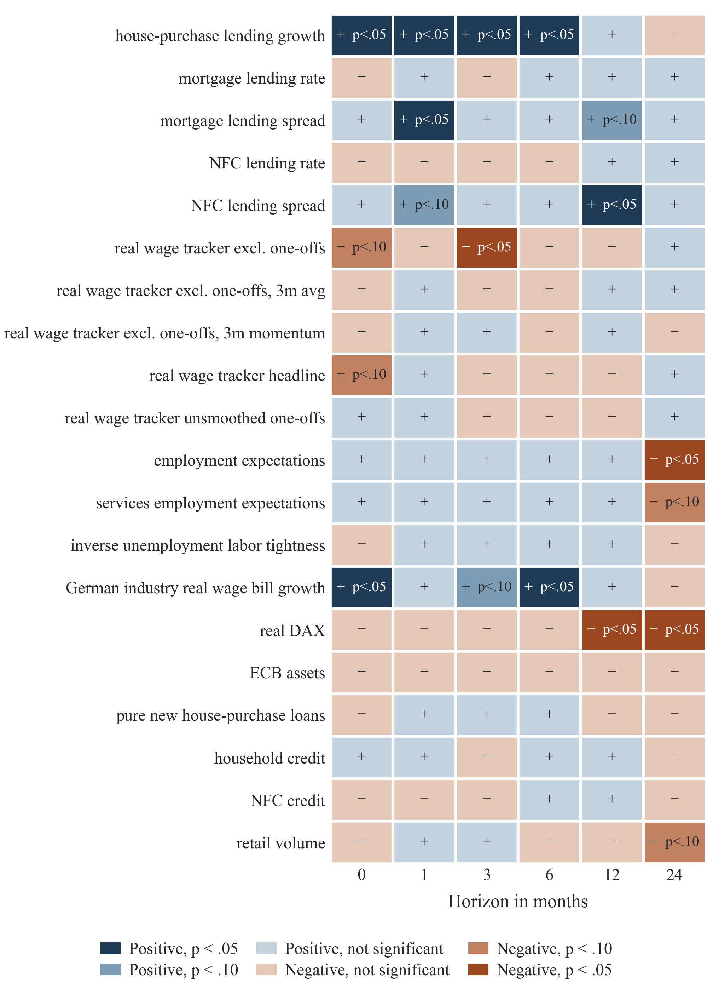

#### Bootstrap Width Comparison


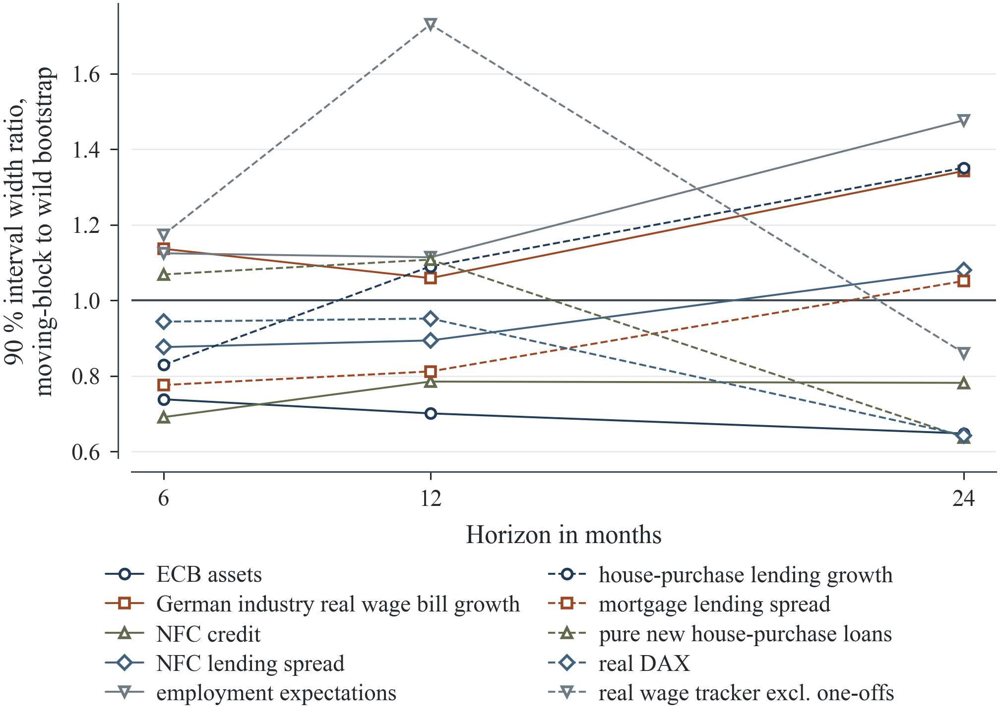

#### Uncertainty Fan: ECB assets


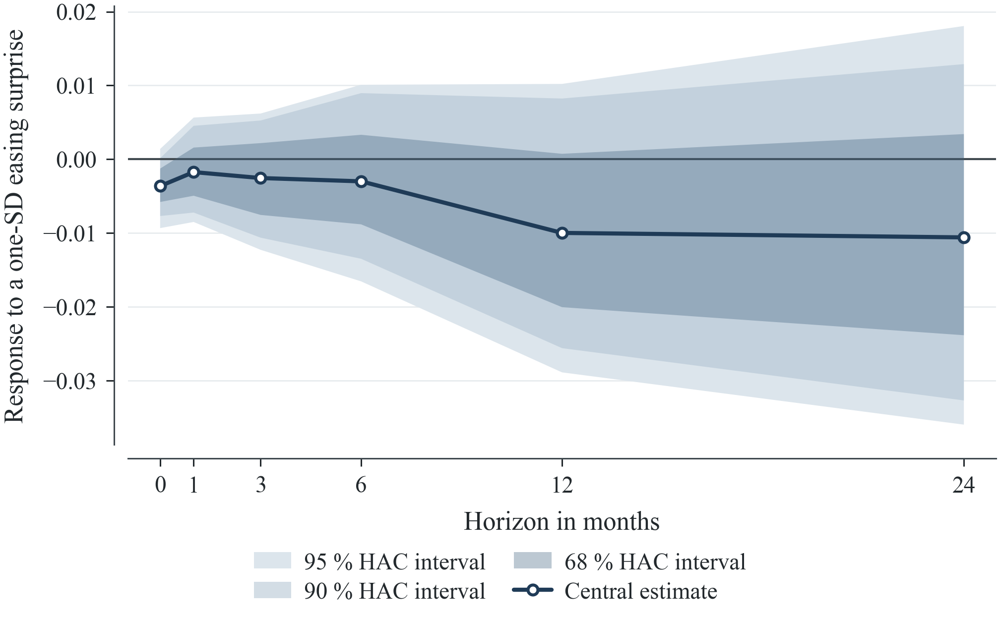

#### Uncertainty Fan: real DAX


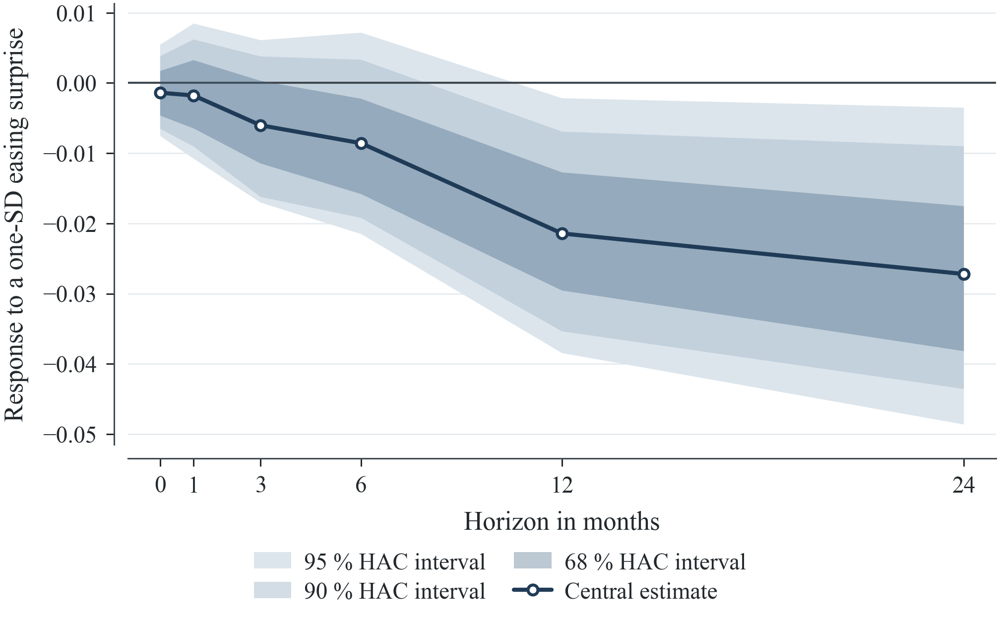

#### Uncertainty Fan: NFC credit


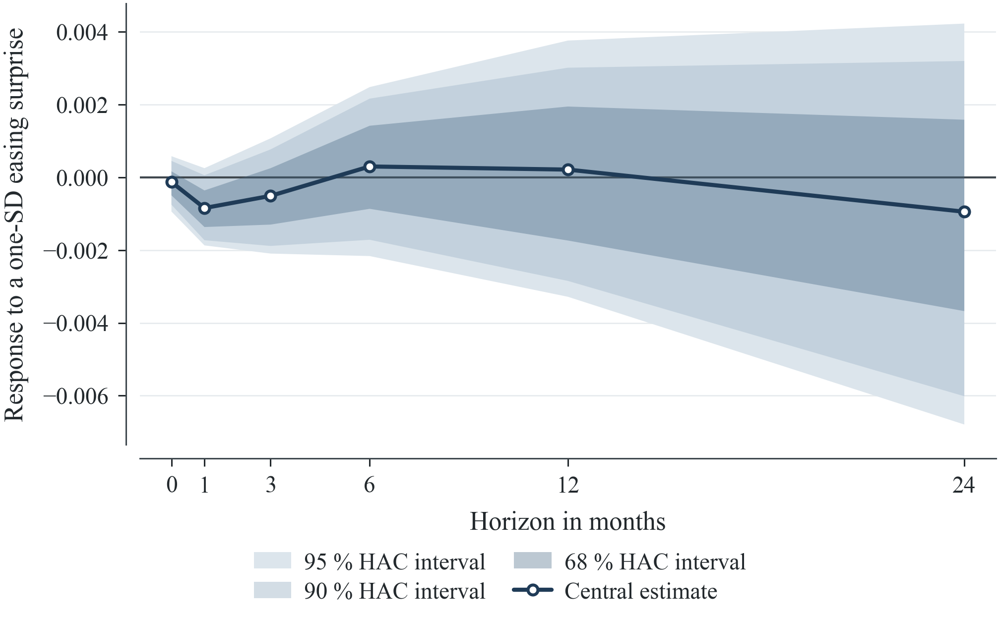

#### Uncertainty Fan: mortgage lending spread


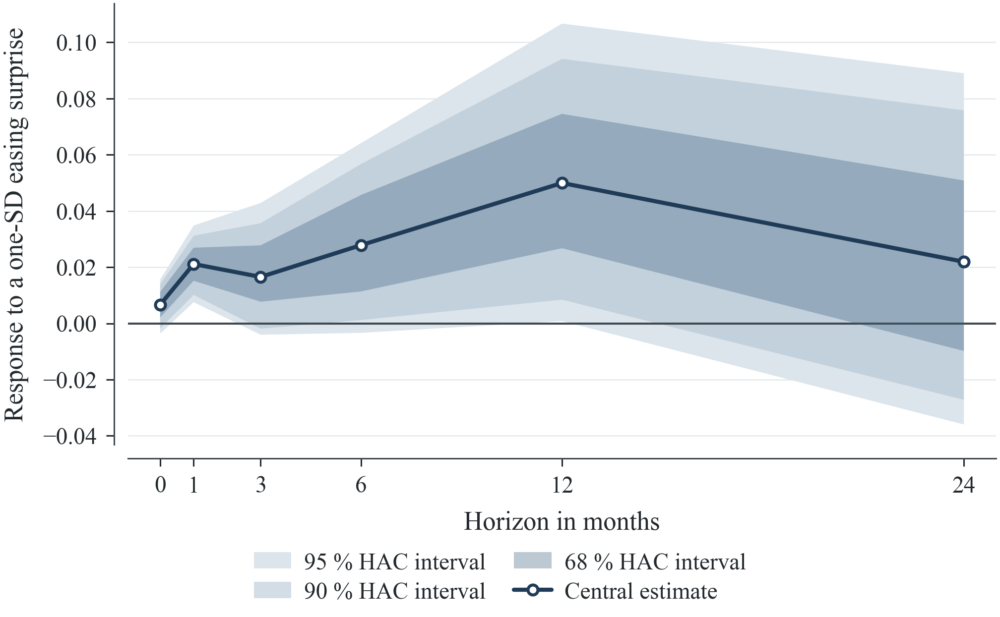

#### Uncertainty Fan: NFC lending spread


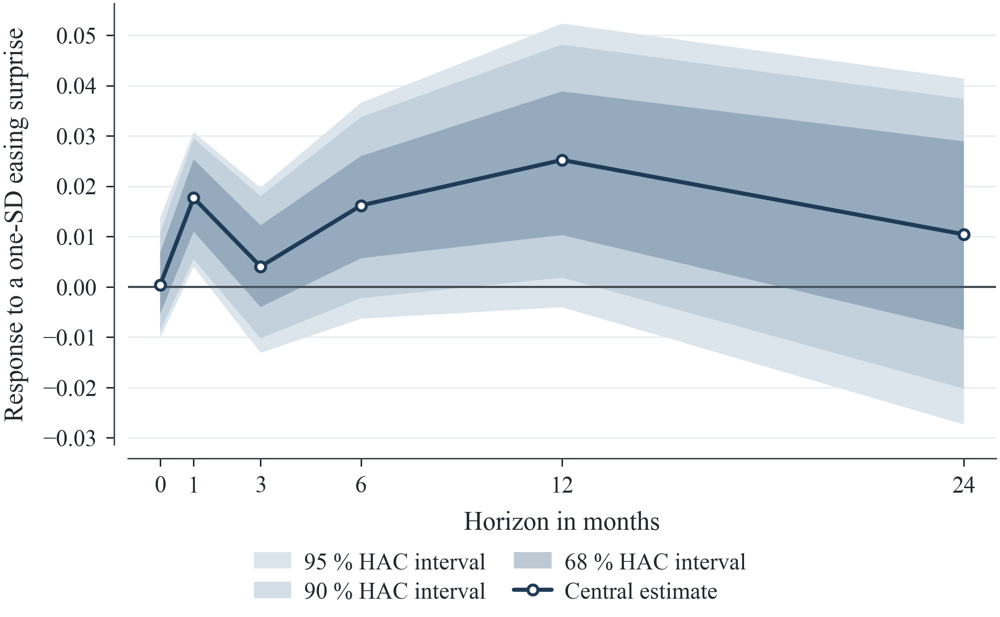

#### Uncertainty Fan: house-purchase lending growth


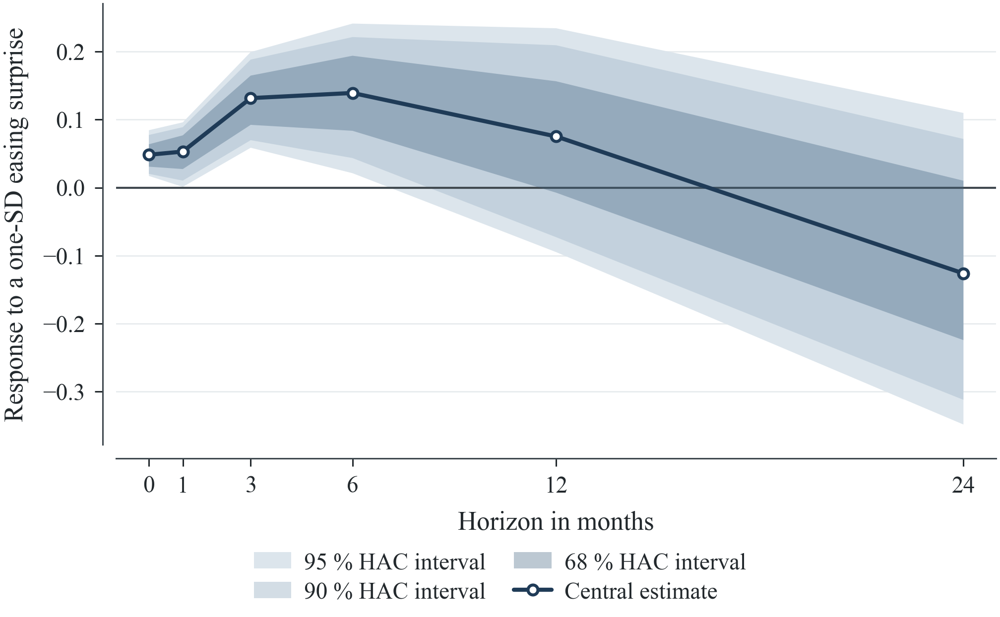

#### Uncertainty Fan: pure new house-purchase loans


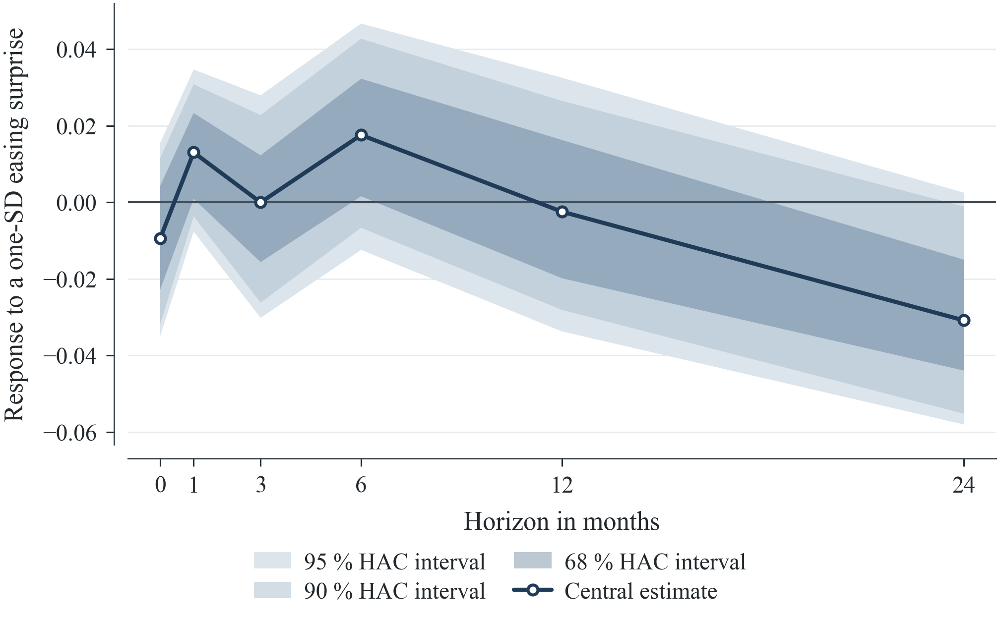

#### Uncertainty Fan: real wage tracker excluding one-offs


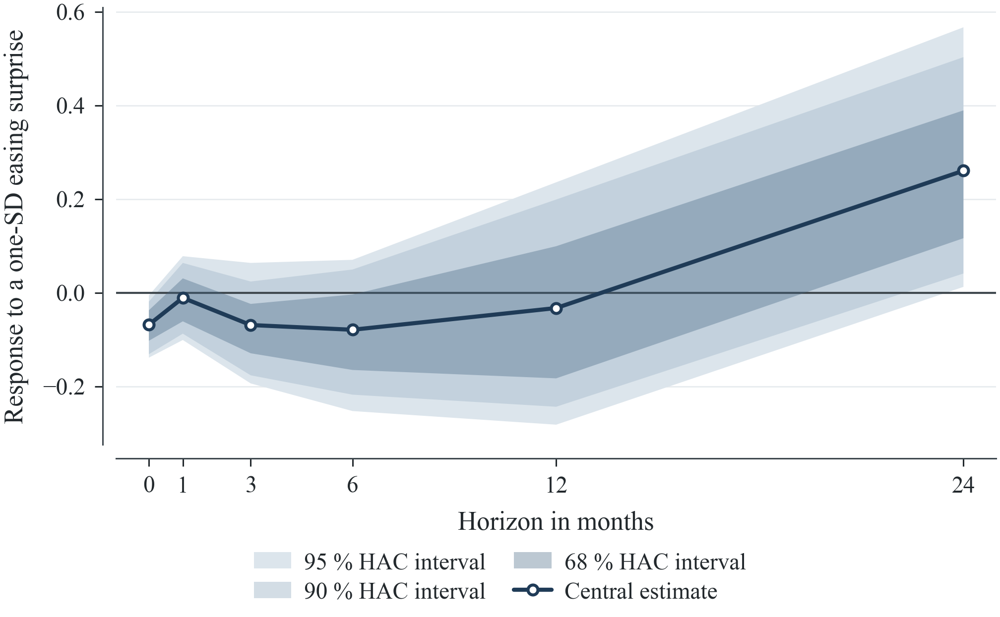

#### Uncertainty Fan: German industry real wage bill growth


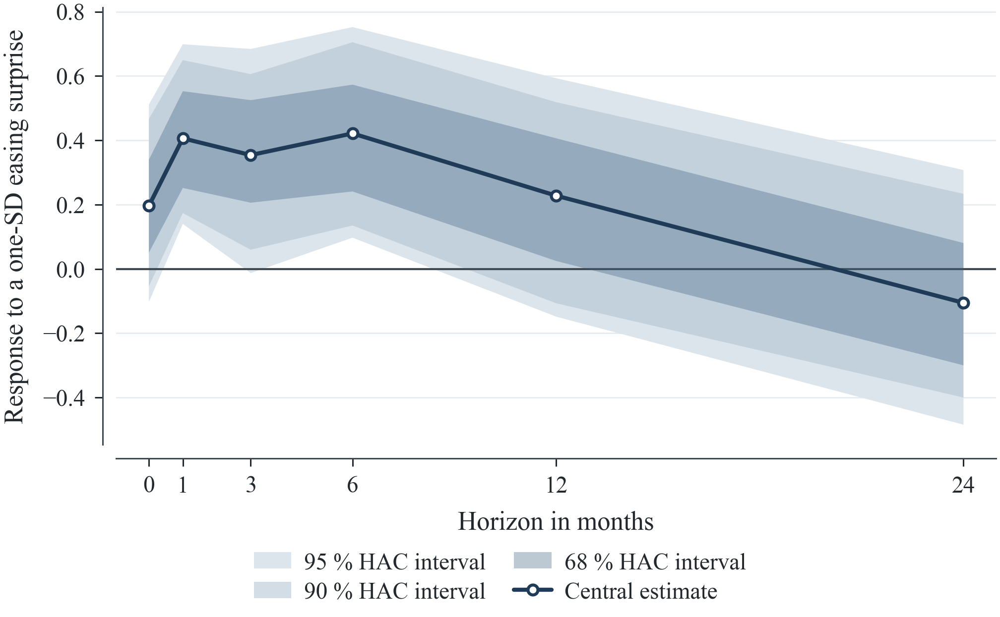

#### Uncertainty Fan: employment expectations


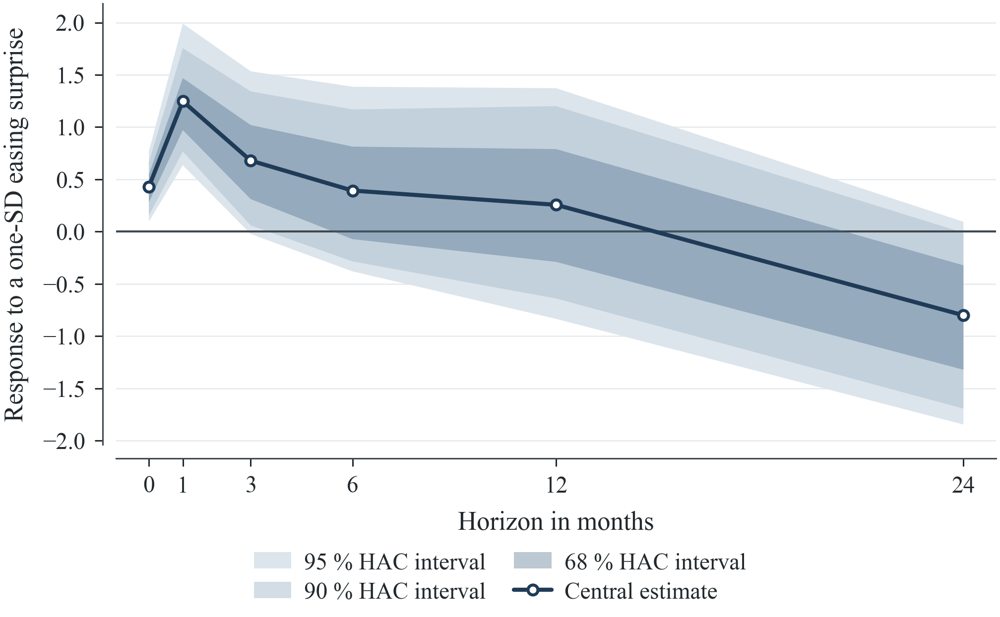

In [15]:
display_uncertainty_matrix_and_figures(empirical_context)


In [16]:
display_robustness_dashboard()


**Clean-Event Robustness**

Variable,Sample,Horizon (months),Response,90 Percent Interval,Direction
house-purchase lending growth,full,6,0.1487,"[0.077, 0.221]",positive
house-purchase lending growth,full,12,0.0986,"[-0.015, 0.212]",positive
house-purchase lending growth,clean_events_only,6,0.0880,"[0.012, 0.164]",positive
house-purchase lending growth,clean_events_only,12,0.1015,"[0.003, 0.200]",positive
house-purchase lending growth,contaminated_events_only,6,0.1226,"[0.055, 0.190]",positive
house-purchase lending growth,contaminated_events_only,12,0.0406,"[-0.057, 0.138]",positive
pure new house-purchase loans,full,6,0.0197,"[-0.002, 0.041]",positive
pure new house-purchase loans,full,12,-0.0013,"[-0.023, 0.020]",negative


**Policy-Rate Comparison**

Variable,Horizon (months),Surprise Lp Sign,Policy Rate Ols Sign,Sign Match,Comparison Use
ECB assets,6,negative,positive,False,qualitative_direction_check_not_causal_measurement review
ECB assets,12,negative,positive,False,qualitative_direction_check_not_causal_measurement review
ECB assets,24,negative,positive,False,qualitative_direction_check_not_causal_measurement review
real DAX,6,negative,positive,False,qualitative_direction_check_not_causal_measurement review
real DAX,12,negative,positive,False,qualitative_direction_check_not_causal_measurement review
real DAX,24,negative,negative,True,qualitative_direction_check_not_causal_measurement review
household credit,6,positive,NaN,False,qualitative_direction_check_not_causal_measurement review
household credit,12,positive,NaN,False,qualitative_direction_check_not_causal_measurement review


**Bootstrap Precision Context**

Variable,Economic channel,Horizon (months),Block Length,Moving Block Width 90,Wild Width 90,Width Ratio Mbb To Wild,Bootstrap Replications
house-purchase lending growth,housing_finance,6,12,0.1780,0.2147,0.8293,399
house-purchase lending growth,housing_finance,12,12,0.2824,0.2591,1.0900,399
house-purchase lending growth,housing_finance,24,12,0.3839,0.2841,1.3510,399
pure new house-purchase loans,housing_finance,6,12,0.0494,0.0462,1.0686,399
pure new house-purchase loans,housing_finance,12,12,0.0546,0.0493,1.1078,399
pure new house-purchase loans,housing_finance,24,12,0.0541,0.0849,0.6374,399
real DAX,financial_market,6,12,0.0225,0.0239,0.9436,399
real DAX,financial_market,12,12,0.0285,0.0299,0.9519,399


**Directional Stability**

Variable,Economic channel,Direction,Sign consistency,Cumulative Direction Consistency,Peak Response Timing Iqr,Response Decay Ratio Abs H24 To H6,Interpretation
mortgage lending spread,banking_lending_conditions,positive,1.0000,1.0000,0.0000,0.8355,Direction is fairly stable; magnitudes are best read comparatively.
NFC lending spread,banking_lending_conditions,positive,0.9048,1.0000,0.0000,0.6153,Direction is fairly stable; magnitudes are best read comparatively.
real DAX,financial_market,negative,0.9048,1.0000,0.0000,3.1103,Direction is fairly stable; magnitudes are best read comparatively.
house-purchase lending growth,housing_finance,positive,0.8571,1.0000,6.0000,0.7218,Direction is fairly stable; magnitudes are best read comparatively.
German industry real wage bill growth,compensation_proxy,positive,0.8095,1.0000,2.5000,0.3041,Direction is fairly stable; magnitudes are best read comparatively.
ECB assets,financial_liquidity,negative,0.7857,0.8571,12.0000,3.1375,Direction is fairly stable; magnitudes are best read comparatively.
employment expectations,labor_tightness,positive,0.7619,0.7857,23.0000,1.2838,Direction is fairly stable; magnitudes are best read comparatively.
real wage tracker excl. one-offs,compensation_proxy,negative,0.6667,0.8571,12.0000,1.8541,Direction is fairly stable; magnitudes are best read comparatively.


**Persistence Ranking**

Persistence rank,Variable,Economic channel,Max Abs Cumulative,Signed Cumulative At Max
1.0000,employment expectations,labor_tightness,2.7618,1.9621
2.0000,German industry real wage bill growth,compensation_proxy,1.5929,1.4876
3.0000,house-purchase lending growth,housing_finance,0.4832,0.3570
4.0000,real wage tracker excl. one-offs,compensation_proxy,0.3019,-0.0414
5.0000,mortgage lending spread,banking_lending_conditions,0.1401,0.1401
6.0000,NFC lending spread,banking_lending_conditions,0.0707,0.0707
7.0000,real DAX,financial_market,0.0668,-0.0668
8.0000,ECB assets,financial_liquidity,0.0323,-0.0323


### Stability And Robustness

#### Robustness Summary


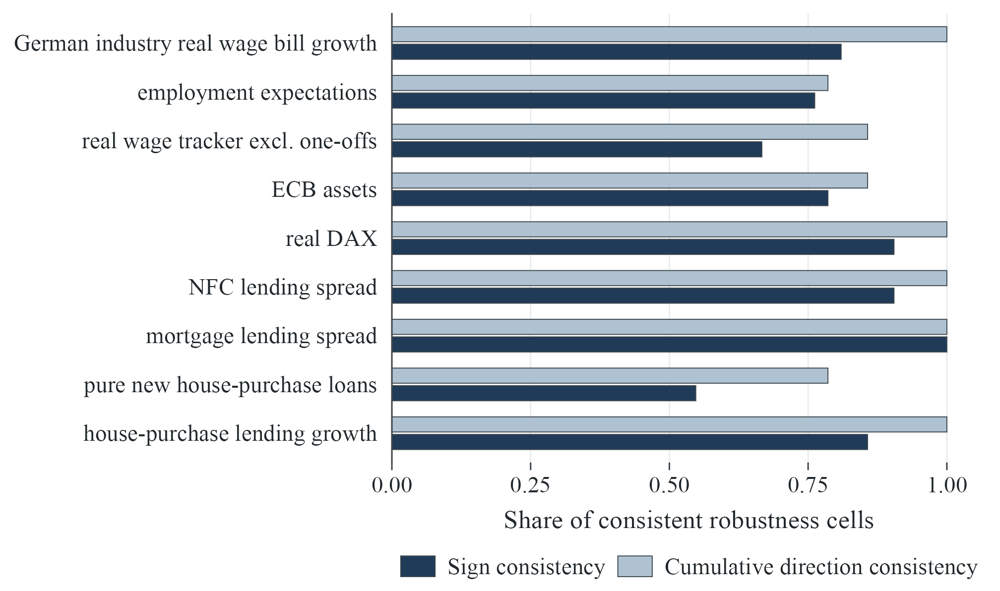

#### Robustness Consistency Matrix


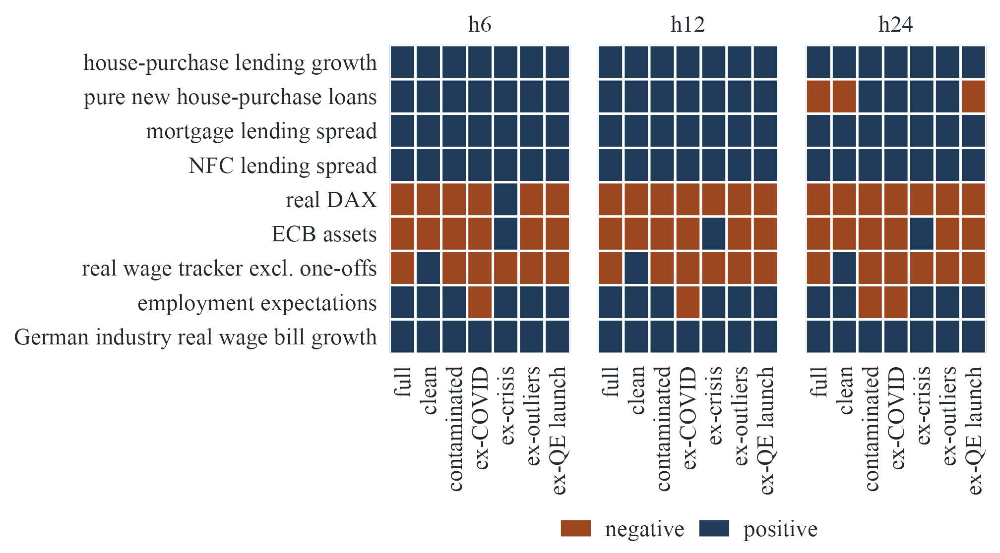

#### Clean Vs Contaminated H6


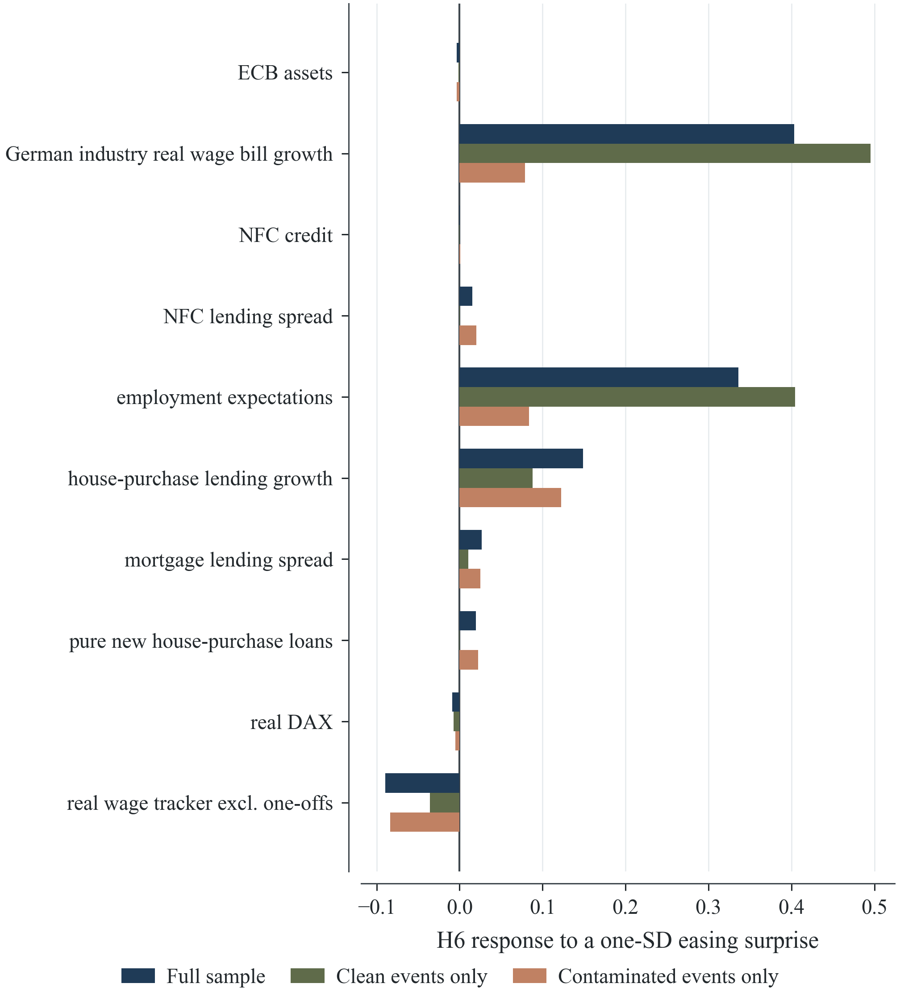

#### Persistence Confidence Matrix


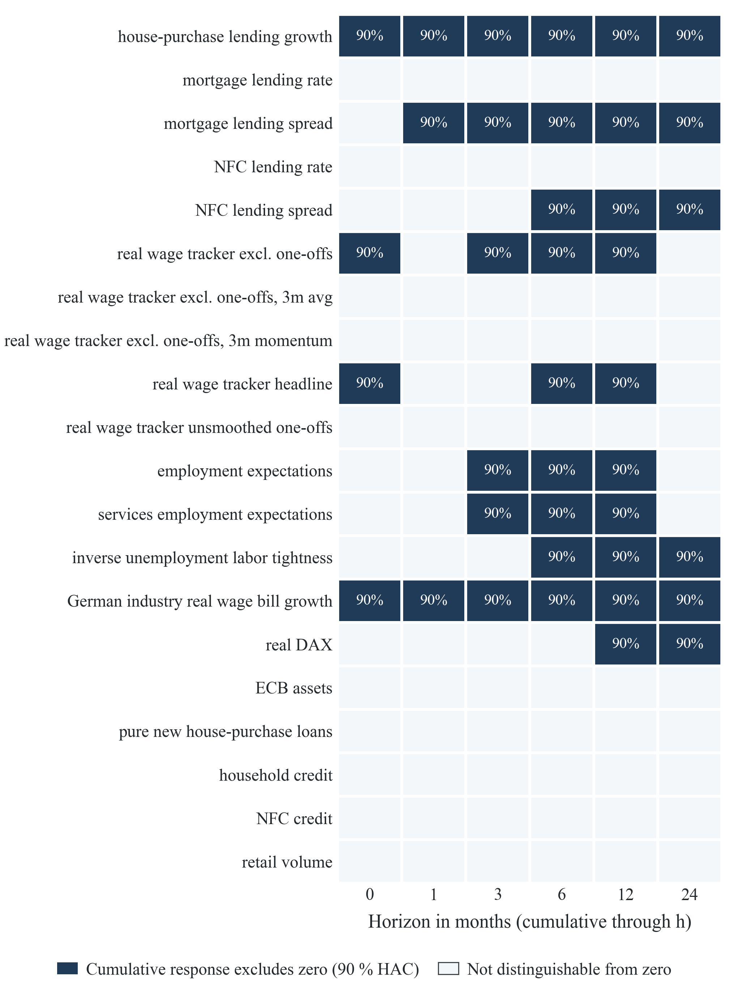

#### Rolling Stability H6 Ecb House Purchase Growth Yoy


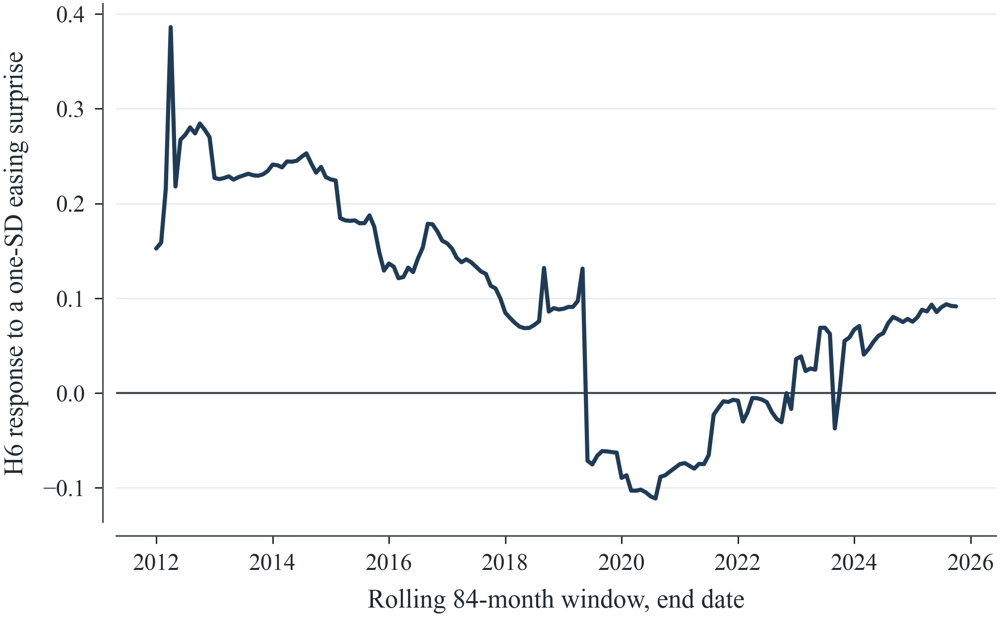

#### Rolling Stability H6 Ln Ecb House Purchase Pure New Loans


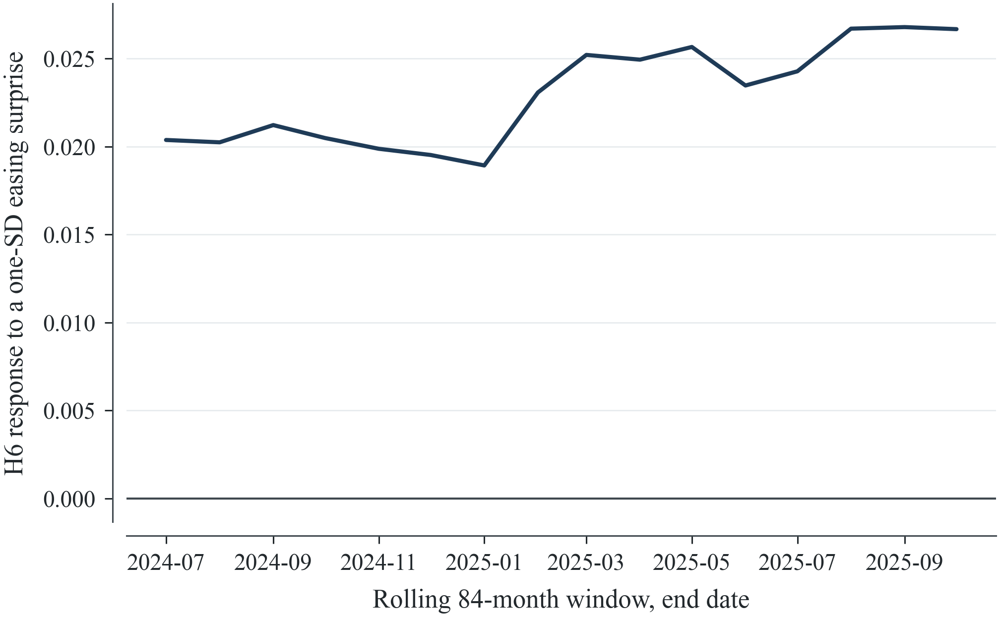

#### Rolling Stability H6 Ecb Wage Tracker Ex Oneoffs Real Yoy


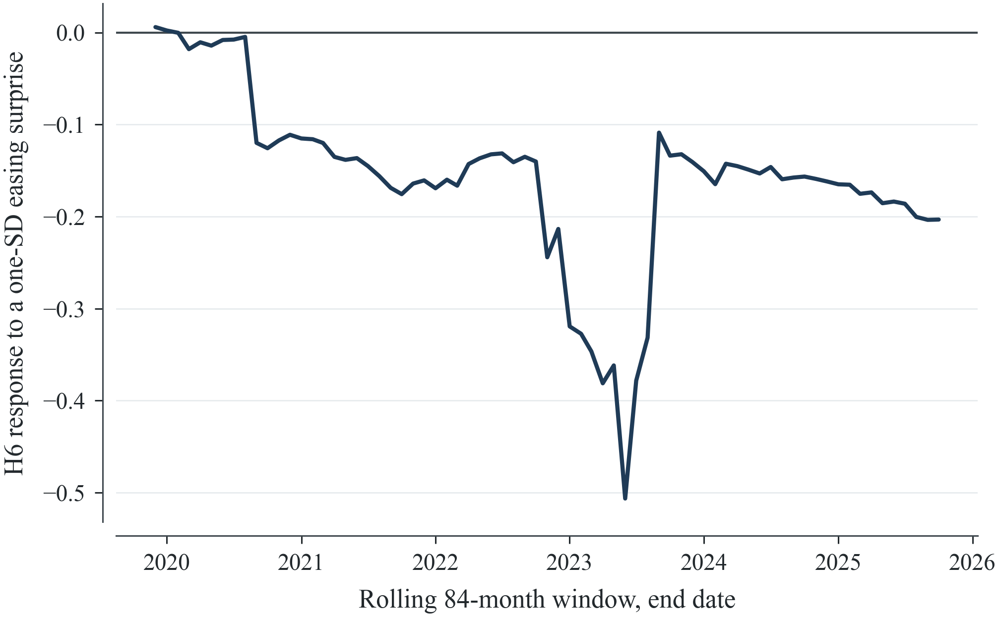

#### Rolling Stability H6 Ln Dax Real De


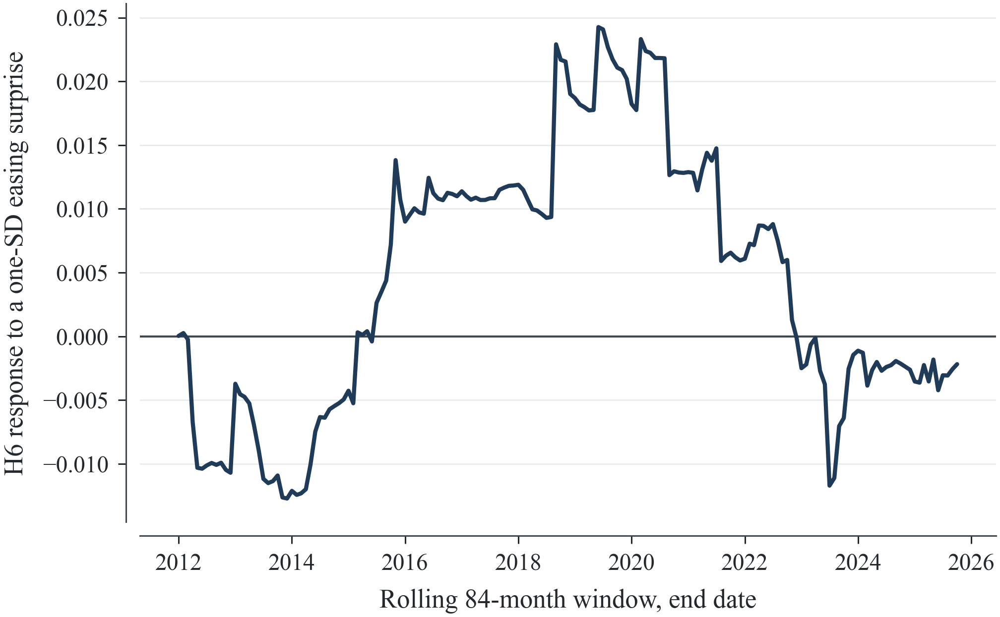

In [17]:
display_stability_dashboard()


**Regime Comparison At 6 Months**

Sample,Variable,Economic channel,Response,90% interval low,90% interval high
regime_covid,CES expected unemployment,labor_tightness,NaN,NaN,NaN
regime_pre_qe,CES expected unemployment,labor_tightness,NaN,NaN,NaN
regime_qe,CES expected unemployment,labor_tightness,NaN,NaN,NaN
regime_tightening,CES expected unemployment,labor_tightness,-0.0223,-0.0517,0.0070
regime_covid,ECB assets,financial_liquidity,NaN,NaN,NaN
regime_pre_qe,ECB assets,financial_liquidity,-0.0074,-0.0181,0.0033
regime_qe,ECB assets,financial_liquidity,-0.0075,-0.0137,-0.0013
regime_tightening,ECB assets,financial_liquidity,0.0007,-0.0035,0.0049


**Regime Cumulative Transmission**

Sample,Variable,Economic channel,Horizon (months),Cumulative response,90% interval low,90% interval high
regime_pre_qe,NFC lending rate,banking_lending_conditions,12,0.1024,-0.0343,0.2392
regime_pre_qe,NFC lending rate,banking_lending_conditions,24,0.1906,-0.0006,0.3819
regime_pre_qe,NFC lending spread,banking_lending_conditions,12,0.0122,-0.0428,0.0672
regime_pre_qe,NFC lending spread,banking_lending_conditions,24,-0.0037,-0.0642,0.0568
regime_pre_qe,mortgage lending rate,banking_lending_conditions,12,-0.0198,-0.0794,0.0398
regime_pre_qe,mortgage lending rate,banking_lending_conditions,24,-0.0030,-0.0796,0.0735
regime_pre_qe,mortgage lending spread,banking_lending_conditions,12,-0.0062,-0.0704,0.0579
regime_pre_qe,mortgage lending spread,banking_lending_conditions,24,-0.0024,-0.0702,0.0653


### Proxy And Regime

#### Compensation Proxy Tournament


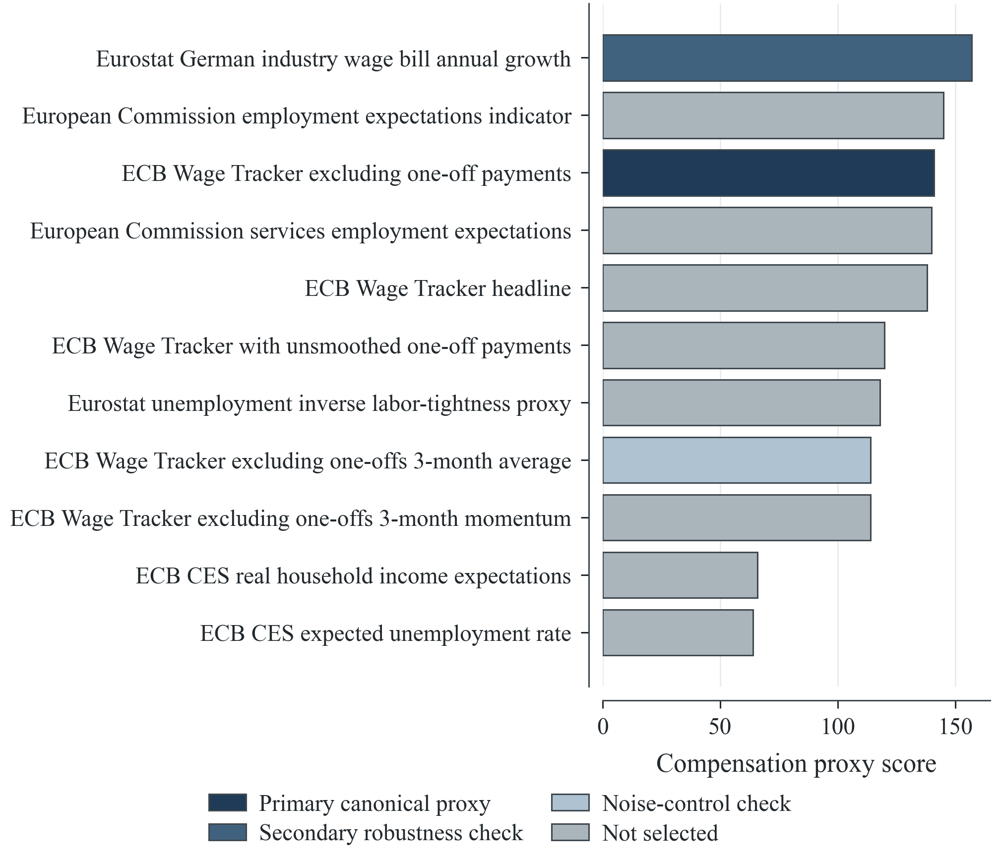

#### Regime Response Comparison


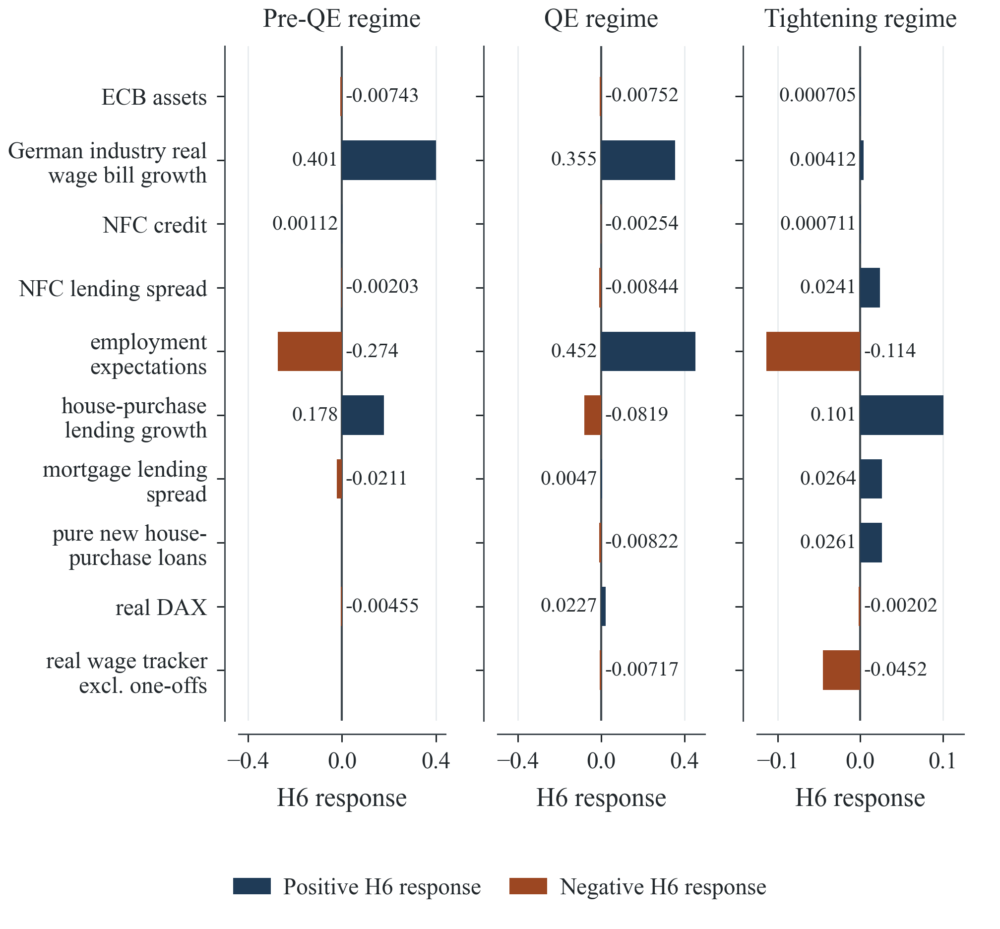

In [18]:
display_regime_analysis()


## 7. Interpretation

Taken together, the evidence supports an asymmetric monetary-transmission narrative. ECB easing surprises transmit strongly into housing finance, lending conditions, and financial-market variables, while compensation-related responses are weaker, less persistent, or more dependent on proxy choice.

The economic implication is important for post-COVID affordability. If liquidity reaches asset prices and housing finance faster than real wages, monetary expansion can raise balance-sheet values without delivering comparable gains in household purchasing power.


In [19]:
display_hypothesis_evaluation(comparison)


**Thesis Hypothesis Readings**

Hypothesis,Reading,Evidence,Interpretation
H1 - Dominant Housing And Asset-Price Transmission,supported in reduced-form terms,"Housing-finance, financial-market, and lending-condition responses are visible in baseline, cumulative, uncertainty, and mechanism outputs.","ECB easing surprises transmit persistently through housing and asset-linked channels, consistent with balance-sheet inflation."
H2 - Productive Credit Channel Is Not The Dominant Post-Shock Path,partially supported / mixed,"NFC credit and lending-condition variables are present, but the strongest persistence evidence is not a clean productive-credit dominance...","Credit intermediation matters for timing, but aggregate macro evidence does not prove that productive lending was the primary expansionar..."
H3 - Real-Economy And Compensation Pass-Through Is Attenuated,supported with proxy context,"Wage-pressure and real-economy proxies generally appear weaker, delayed, or less persistent than financial/housing-finance responses.",The dynamic response hierarchy is consistent with financial-channel dominance and real-economy attenuation.


**Housing, Financial, And Asset-Linked Evidence**

Variable,Economic channel,Peak response,Peak horizon,Visible horizons,24-month cumulative response,Persistence reading
NFC lending rate,banking_lending_conditions,0.0375,24,0,0.0128,limited / uncertain
NFC lending spread,banking_lending_conditions,0.0252,12,2,0.0707,persistent cumulative
mortgage lending rate,banking_lending_conditions,0.0338,24,0,0.0600,limited / uncertain
mortgage lending spread,banking_lending_conditions,0.0500,12,2,0.1401,persistent cumulative
ECB assets,financial_liquidity,-0.0106,24,0,-0.0323,limited / uncertain
real DAX,financial_market,-0.0272,24,2,-0.0668,persistent cumulative
house-purchase lending growth,housing_finance,0.1487,6,4,0.3570,persistent cumulative
pure new house-purchase loans,housing_finance,-0.0308,24,0,-0.0055,limited / uncertain


**Productive-Credit And Real-Activity Evidence**

Variable,Economic channel,Peak response,Peak horizon,Visible horizons,24-month cumulative response,Persistence reading
NFC credit,financial_credit,-0.0009,24,0,-0.0019,limited / uncertain
household credit,financial_credit,-0.0014,24,0,-0.0011,limited / uncertain
retail volume,real_activity,-0.0042,24,1,-0.0047,limited / uncertain


**Compensation And Labor-Market Evidence**

Variable,Economic channel,Peak response,Peak horizon,Visible horizons,24-month cumulative response,Persistence reading
German industry real wage bill growth,compensation_proxy,0.4220,1,3,1.4876,persistent cumulative
real wage tracker excl. one-offs,compensation_proxy,0.2605,24,2,-0.0414,multi-horizon visible
"real wage tracker excl. one-offs, 3m avg",compensation_proxy,0.2318,24,0,0.2279,limited / uncertain
"real wage tracker excl. one-offs, 3m momentum",compensation_proxy,0.0324,12,0,0.0038,limited / uncertain
real wage tracker headline,compensation_proxy,0.2654,24,1,0.0334,limited / uncertain
real wage tracker unsmoothed one-offs,compensation_proxy,0.2248,24,0,0.1285,limited / uncertain
employment expectations,labor_tightness,1.1731,1,1,1.9621,limited / uncertain
inverse unemployment labor tightness,labor_tightness,0.0631,12,0,0.1377,persistent cumulative


## Final Thesis-Level Conclusion

The final empirical record supports the central thesis: expansionary monetary policy transmits more strongly into housing, financial assets, lending conditions, and balance-sheet channels than into real compensation dynamics.

The wage and compensation evidence is not absent, but it is weaker and less consistent than the housing and asset-linked evidence. This asymmetry is the key empirical contribution of the notebook and the main economic interpretation carried into the thesis.


## Appendix: Replication Notes

The following cells retain replication context, source documentation, and specification details for readers who want to inspect the computational environment. They are hidden by default so the main notebook reads as an empirical thesis appendix rather than a technical operations report.


In [20]:
if SHOW_REPLICATION_APPENDIX:
    display_source_manifest()
    display_reproducibility_header()
    display_specification_registry(empirical_context)
    final_integrity = display_final_validation(major_output_status)
